<h1 align="center"><font size="5">Project: Review analysis - Review analysis of Amazon Kindle Book Review</font></h1>

Dataset: all_kindle_review.csv

#### Data dictionary:

* asin - ID of the product, like B000FA64PK
* helpful - helpfulness rating of the review - example: 2/3.
* overall - rating of the product.
* reviewText - text of the review (heading).
* reviewTime - time of the review (raw).
* reviewerID - ID of the reviewer, like A3SPTOKDG7WBLN
* reviewerName - name of the reviewer.
* summary - summary of the review (description).
* unixReviewTime - unix timestamp.

# Assignment1

## Set-up

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATA_PATH = '/content/drive/MyDrive/P4AIDS-Assignment/Text/input_data/all_kindle_review.csv'

## Import library

In [ ]:
!pip install -q langdetect
!pip install -q wordcloud
!pip install -q textblob
!pip install -q imbalanced-learn
!pip install -q xgboost
!pip install -q transformers datasets evaluate
!pip install -q accelerate -U
!pip install -q underthesea
!pip install -q gensim

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 4.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 996.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 24.3 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import string
import time
import os
import psutil
from tqdm import tqdm
import torch.optim as optim
import seaborn as sns
from wordcloud import WordCloud
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, f1_score
from textblob import Word
from sklearn.pipeline import Pipeline
from sklearn import metrics
from sklearn.metrics.pairwise import cosine_similarity
from langdetect import detect

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB  #
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC #
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.base import clone
import xgboost as xgb

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report
import numpy as np
import copy

In [ ]:
import torch
import re
import torch.nn as nn
from underthesea import word_tokenize
from gensim.models import Word2Vec
from torch.nn.utils.rnn import pad_sequence

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from collections import Counter
from nltk.corpus import stopwords

In [ ]:
SEED = 42

## Read and overview dataset

In [ ]:
data = pd.read_csv(DATA_PATH)
data.head(5)

,Unnamed: 0.1,Unnamed: 0,asin,helpful,rating,reviewText,reviewTime,reviewerID,reviewerName,summary,unixReviewTime
0,0,11539,B0033UV8HI,"[8, 10]",3,"Jace Rankin may be short, but he's nothing to ...","09 2, 2010",A3HHXRELK8BHQG,Ridley,Entertaining But Average,1283385600
1,1,5957,B002HJV4DE,"[1, 1]",5,Great short read. I didn't want to put it dow...,"10 8, 2013",A2RGNZ0TRF578I,Holly Butler,Terrific menage scenes!,1381190400
2,2,9146,B002ZG96I4,"[0, 0]",3,I'll start by saying this is the first of four...,"04 11, 2014",A3S0H2HV6U1I7F,Merissa,Snapdragon Alley,1397174400
3,3,7038,B002QHWOEU,"[1, 3]",3,Aggie is Angela Lansbury who carries pocketboo...,"07 5, 2014",AC4OQW3GZ919J,Cleargrace,very light murder cozy,1404518400
4,4,1776,B001A06VJ8,"[0, 1]",4,I did not expect this type of book to be in li...,"12 31, 2012",A3C9V987IQHOQD,Rjostler,Book,1356912000


In [ ]:
data = data.loc[:, ~data.columns.str.contains("^Unnamed")]
data.head(5)

,asin,helpful,rating,reviewText,reviewTime,reviewerID,reviewerName,summary,unixReviewTime
0,B0033UV8HI,"[8, 10]",3,"Jace Rankin may be short, but he's nothing to ...","09 2, 2010",A3HHXRELK8BHQG,Ridley,Entertaining But Average,1283385600
1,B002HJV4DE,"[1, 1]",5,Great short read. I didn't want to put it dow...,"10 8, 2013",A2RGNZ0TRF578I,Holly Butler,Terrific menage scenes!,1381190400
2,B002ZG96I4,"[0, 0]",3,I'll start by saying this is the first of four...,"04 11, 2014",A3S0H2HV6U1I7F,Merissa,Snapdragon Alley,1397174400
3,B002QHWOEU,"[1, 3]",3,Aggie is Angela Lansbury who carries pocketboo...,"07 5, 2014",AC4OQW3GZ919J,Cleargrace,very light murder cozy,1404518400
4,B001A06VJ8,"[0, 1]",4,I did not expect this type of book to be in li...,"12 31, 2012",A3C9V987IQHOQD,Rjostler,Book,1356912000


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   asin            12000 non-null  object
 1   helpful         12000 non-null  object
 2   rating          12000 non-null  int64 
 3   reviewText      12000 non-null  object
 4   reviewTime      12000 non-null  object
 5   reviewerID      12000 non-null  object
 6   reviewerName    11962 non-null  object
 7   summary         11998 non-null  object
 8   unixReviewTime  12000 non-null  int64 
dtypes: int64(2), object(7)
memory usage: 843.9+ KB


In [ ]:
data.describe()

,rating,unixReviewTime
count,12000.000000,1.200000e+04
mean,3.250000,1.344537e+09
std,1.421619,4.369374e+07
min,1.000000,9.602496e+08
25%,2.000000,1.316218e+09
50%,3.500000,1.356826e+09
75%,4.250000,1.376870e+09
max,5.000000,1.405814e+09


In [ ]:
print("===== DATASET OVERVIEW =====")

num_samples = len(data)
num_categories = data['rating'].nunique()
missing = data.isnull().sum()

data['word_count'] = data['reviewText'].astype(str).apply(lambda x: len(x.split()))
data['char_count'] = data['reviewText'].astype(str).apply(len)

avg_words = data['word_count'].mean()
avg_chars = data['char_count'].mean()

print(f"Samples: {num_samples}")
print(f"Categories (rating): {num_categories}")
print(f"Avg words / review: {avg_words:.2f}")
print(f"Avg chars / review: {avg_chars:.2f}")

print("\n===== MISSING VALUES =====")
print(missing)

===== DATASET OVERVIEW =====
Samples: 12000
Categories (rating): 5
Avg words / review: 109.24
Avg chars / review: 601.56

===== MISSING VALUES =====
asin               0
helpful            0
rating             0
reviewText         0
reviewTime         0
reviewerID         0
reviewerName      38
summary            2
unixReviewTime     0
dtype: int64


In [ ]:
print(data.columns)

Index(['asin', 'helpful', 'rating', 'reviewText', 'reviewTime', 'reviewerID',
       'reviewerName', 'summary', 'unixReviewTime', 'word_count',
       'char_count'],
      dtype='object')


In [ ]:
# xem vài mẫu
for r, grp in data.groupby('rating'):
  print("="*25)
  print(f'sample for rating {r}:', grp['reviewText'].iloc[0])
  print("="*25)

sample for rating 1: I received a copy of book to review. "A secret society. A fanatical cult. A telepathic girl." are not my cup of tea. This was not what I expected and I really don't need another continuational book. I still haven't read the Catching Fire from the Hunger Games. I don't get into all this sci-fi stuff. Just not my cup of tea. Sorry.
sample for rating 2: This has the makings of a good story... unfortunately it disappoints.it tells of two alpha were who are members of unfriendly packs... they have grown up together with one being gay and the other straight... then when it seems they are about to get together something happens and the story is told in alternating chapters of past and present.. the story and the couple fall apart in the switch of time and lack of a sustainable reason for the break.
sample for rating 3: Jace Rankin may be short, but he's nothing to mess with, as the man who was just hauled out of the saloon by the undertaker knows now. He's a famous bounty

## Rating Distribution

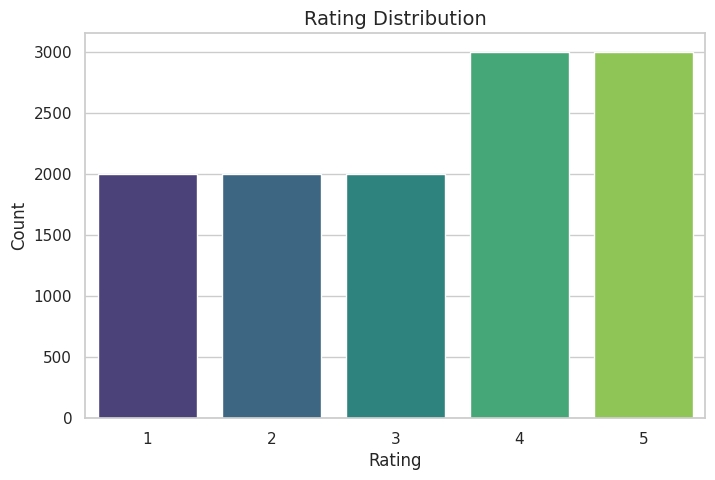

In [ ]:
sns.set(style="whitegrid")
plt.figure(figsize=(8,5))
sns.countplot(x='rating', data=data, palette='viridis')
plt.title("Rating Distribution", fontsize=14)
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

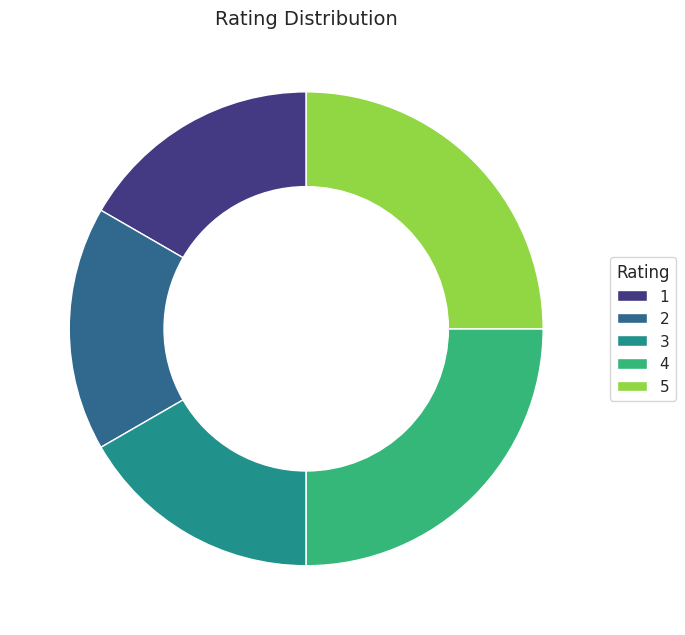

In [ ]:
rating_counts = data['rating'].value_counts().sort_index()
colors = sns.color_palette("viridis", len(rating_counts))

plt.figure(figsize=(7,7))

wedges, texts = plt.pie(
    rating_counts,
    colors=colors,
    startangle=90,
    wedgeprops=dict(width=0.4, edgecolor='white')  # ace donut
)

plt.legend(
    wedges,
    rating_counts.index,
    title="Rating",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Rating Distribution", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
data.rating.value_counts()

,count
rating,
5,3000
4,3000
3,2000
2,2000
1,2000


Star >= 3 would be positive, others must be negative

In [ ]:
data['sentiment'] = data['rating'].apply(lambda x: 1 if x>=3 else 0)

In [ ]:
data.head()

,asin,helpful,rating,reviewText,reviewTime,reviewerID,reviewerName,summary,unixReviewTime,word_count,char_count,sentiment
0,B0033UV8HI,"[8, 10]",3,"Jace Rankin may be short, but he's nothing to ...","09 2, 2010",A3HHXRELK8BHQG,Ridley,Entertaining But Average,1283385600,541,2921,1
1,B002HJV4DE,"[1, 1]",5,Great short read. I didn't want to put it dow...,"10 8, 2013",A2RGNZ0TRF578I,Holly Butler,Terrific menage scenes!,1381190400,69,371,1
2,B002ZG96I4,"[0, 0]",3,I'll start by saying this is the first of four...,"04 11, 2014",A3S0H2HV6U1I7F,Merissa,Snapdragon Alley,1397174400,76,416,1
3,B002QHWOEU,"[1, 3]",3,Aggie is Angela Lansbury who carries pocketboo...,"07 5, 2014",AC4OQW3GZ919J,Cleargrace,very light murder cozy,1404518400,54,336,1
4,B001A06VJ8,"[0, 1]",4,I did not expect this type of book to be in li...,"12 31, 2012",A3C9V987IQHOQD,Rjostler,Book,1356912000,20,90,1


In [ ]:
data.sentiment.value_counts()

,count
sentiment,
1,8000
0,4000


Seem that we have imbalance dataset problem, need to handle in later step

In [ ]:
# if 'word_count' not in data.columns:
#     data['word_count'] = data['reviewText'].astype(str).apply(lambda x: len(x.split()))

stats = data.groupby('rating').agg(
    Count=('rating', 'count'),
    Avg_Words=('word_count', 'mean')
).reset_index()

stats.columns = ['Category', 'Count', 'Avg Words']
stats['Percentage'] = stats['Count'] / stats['Count'].sum() * 100

stats['Percentage'] = stats['Percentage'].map(lambda x: f"{x:.1f}%")
stats['Avg Words'] = stats['Avg Words'].map(lambda x: f"{x:.1f}")

stats = stats[['Category', 'Count', 'Percentage', 'Avg Words']]

stats.style \
    .background_gradient(cmap='Blues', subset=['Count']) \
    .background_gradient(cmap='YlGn', subset=['Avg Words']) \
    .set_properties(**{
        'text-align': 'center',
        'font-size': '12pt'
    }) \
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('font-size', '13pt'),
                ('text-align', 'center'),
                ('background-color', '#40466e'),
                ('color', 'white')
            ]
        }
    ]) \
    .set_caption("Dataset Statistics by Rating")

,Category,Count,Percentage,Avg Words
0,1,2000,16.7%,96.1
1,2,2000,16.7%,115.2
2,3,2000,16.7%,119.3
3,4,3000,25.0%,119.4
4,5,3000,25.0%,97.1


## Stopword analysis

In [ ]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

all_words = " ".join(data['reviewText'].astype(str)).lower().split()
stopword_list = [word for word in all_words if word in stop_words]
stopword_counts = Counter(stopword_list)

top10 = stopword_counts.most_common(10)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


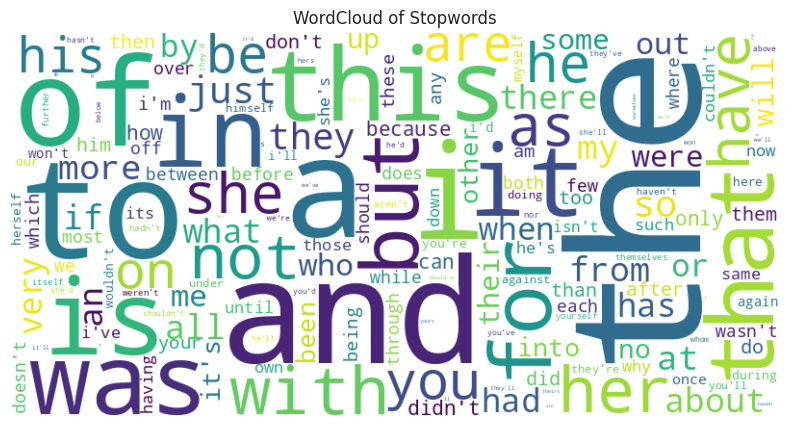

In [ ]:
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate_from_frequencies(stopword_counts)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud of Stopwords')
plt.show()

In [ ]:
total_words = len(all_words)
total_stopwords = len(stopword_list)

percent_stopwords = (total_stopwords / total_words) * 100

print(f"Total words: {total_words}")
print(f"Total stopwords: {total_stopwords}")
print(f"Percentage of stopwords: {percent_stopwords:.2f}%")

Total words: 1310842
Total stopwords: 644325
Percentage of stopwords: 49.15%


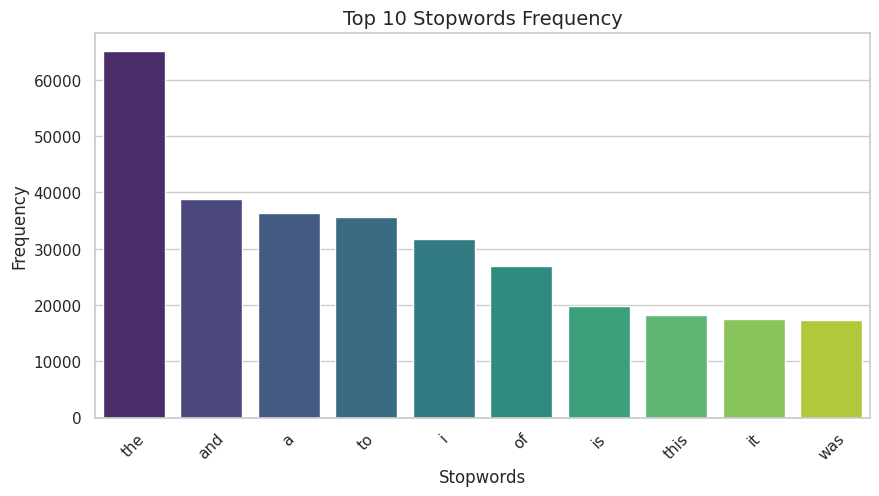

In [ ]:
words = [w for w, _ in top10]
counts = [c for _, c in top10]

sns.set(style="whitegrid")

plt.figure(figsize=(10,5))
sns.barplot(x=words, y=counts, palette='viridis')

plt.title("Top 10 Stopwords Frequency", fontsize=14)
plt.xlabel("Stopwords")
plt.ylabel("Frequency")

plt.xticks(rotation=45)
plt.show()

In [ ]:
top30 = stopword_counts.most_common(50)

for i, (word, _) in enumerate(top30, 1):
    print(word, end=', ')
    if i % 10 == 0:
        print()

the, and, a, to, i, of, is, this, it, was, 
in, that, for, but, with, her, not, have, as, she, 
he, you, be, on, are, his, just, so, they, at, 
my, more, all, an, from, about, if, what, had, there, 
has, very, by, when, or, out, me, who, were, some, 


## Word & Char Count Distribution

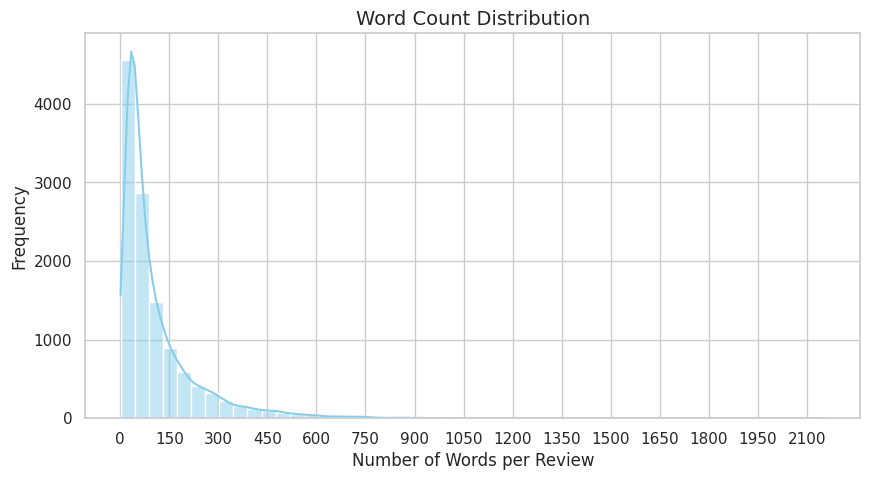

In [ ]:
sns.set(style="whitegrid")

plt.figure(figsize=(10,5))

sns.histplot(
    data['word_count'],
    bins=50,
    kde=True,
    color='skyblue'
)

max_val = data['word_count'].max()
plt.xticks(np.arange(0, max_val, 150))

plt.title("Word Count Distribution", fontsize=14)
plt.xlabel("Number of Words per Review")
plt.ylabel("Frequency")

plt.show()

## Pre-processing data for further analysis

#### Convert to lower case

In [ ]:
data_cleaned = data.copy()

In [ ]:
data_cleaned.reviewText = data_cleaned['reviewText'].apply(lambda x: x.lower())
data_cleaned.reviewText.head()

,reviewText
0,"jace rankin may be short, but he's nothing to ..."
1,great short read. i didn't want to put it dow...
2,i'll start by saying this is the first of four...
3,aggie is angela lansbury who carries pocketboo...
4,i did not expect this type of book to be in li...


#### Check duplicate and remove

In [ ]:
data_cleaned.reviewText.duplicated().sum()

np.int64(0)

No duplicated data

#### Check missing values

In [ ]:
data_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   asin            12000 non-null  object
 1   helpful         12000 non-null  object
 2   rating          12000 non-null  int64 
 3   reviewText      12000 non-null  object
 4   reviewTime      12000 non-null  object
 5   reviewerID      12000 non-null  object
 6   reviewerName    11962 non-null  object
 7   summary         11998 non-null  object
 8   unixReviewTime  12000 non-null  int64 
 9   word_count      12000 non-null  int64 
 10  char_count      12000 non-null  int64 
 11  sentiment       12000 non-null  int64 
dtypes: int64(5), object(7)
memory usage: 1.1+ MB


Missing values here is not considered

#### Check Language of review

In [ ]:
tqdm.pandas()
df_check_lang = data_cleaned['reviewText'].progress_apply(detect)

100%|██████████| 12000/12000 [00:59<00:00, 201.47it/s]


In [ ]:
df_check_lang.value_counts()

,count
reviewText,
en,11992
af,4
cs,1
sl,1
no,1
es,1


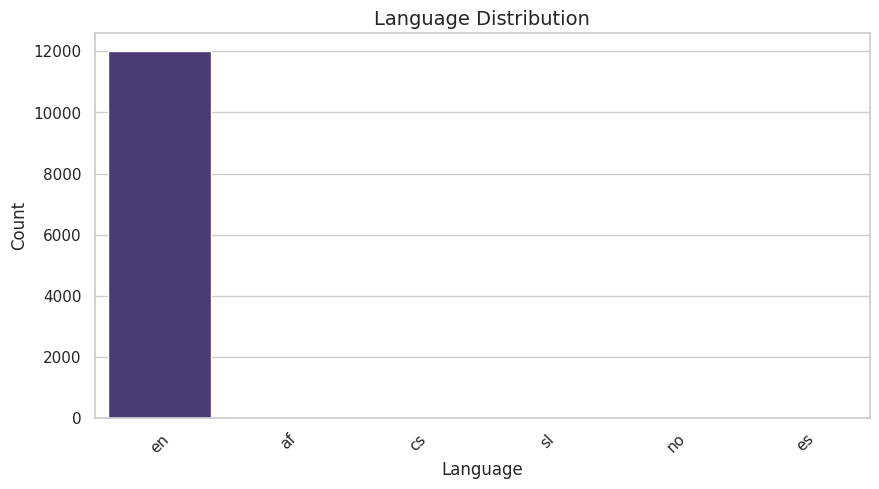

In [ ]:
sns.set(style="whitegrid")
lang_counts = df_check_lang.value_counts()

plt.figure(figsize=(10,5))

sns.barplot(
    x=lang_counts.index,
    y=lang_counts.values,
    palette='viridis'
)

plt.title("Language Distribution", fontsize=14)
plt.xlabel("Language")
plt.ylabel("Count")

plt.xticks(rotation=45)
plt.show()

* Most of language is english, need to remove others

In [ ]:
data_cleaned = data_cleaned[df_check_lang=='en']

#### Removing Punctuation

In [ ]:
data_cleaned.reviewText = data_cleaned['reviewText'].apply(lambda x: ''.join(char for char in x if char not in string.punctuation))
data_cleaned.reviewText.head()

,reviewText
0,jace rankin may be short but hes nothing to me...
1,great short read i didnt want to put it down ...
2,ill start by saying this is the first of four ...
3,aggie is angela lansbury who carries pocketboo...
4,i did not expect this type of book to be in li...


#### Replace Numbers with a Space

In [ ]:
data_cleaned.reviewText = data_cleaned.reviewText.str.replace('\d+', ' ', regex=True)
data_cleaned.reviewText = data_cleaned.reviewText.str.replace('\s+', ' ', regex=True)
data_cleaned.reviewText.head()

,reviewText
0,jace rankin may be short but hes nothing to me...
1,great short read i didnt want to put it down s...
2,ill start by saying this is the first of four ...
3,aggie is angela lansbury who carries pocketboo...
4,i did not expect this type of book to be in li...


#### Remove stopword

In [ ]:
stop_words = set(stopwords.words('english'))

data_cleaned['reviewText'] = data_cleaned['reviewText'].apply(
    lambda x: ' '.join(word for word in x.split() if word not in stop_words)
)

In [ ]:
data_cleaned.reviewText.head()

,reviewText
0,jace rankin may short hes nothing mess man hau...
1,great short read didnt want put read one sitti...
2,ill start saying first four books wasnt expect...
3,aggie angela lansbury carries pocketbooks inst...
4,expect type book library pleased find price right


#### Lemmatization

In [ ]:
nltk.download('wordnet')
lemma = WordNetLemmatizer()
data.reviewText = data.reviewText.apply(lambda x: ' '.join(lemma.lemmatize(word) for word in x.split()))
data.reviewText.head()

[nltk_data] Downloading package wordnet to /root/nltk_data...


,reviewText
0,"Jace Rankin may be short, but he's nothing to ..."
1,Great short read. I didn't want to put it down...
2,I'll start by saying this is the first of four...
3,Aggie is Angela Lansbury who carry pocketbook ...
4,I did not expect this type of book to be in li...


In [ ]:
data_cleaned['tokens'] = data_cleaned['reviewText'].apply(lambda x: x.split())

## Vocabulary and Meaningful Words

In [ ]:
stats = []

for rating, group in data_cleaned.groupby('rating'):
    all_words = [w for tokens in group['tokens'] for w in tokens]

    total_words = len(all_words)
    unique_words = len(set(all_words))
    reviews = len(group)

    stats.append([rating, total_words, unique_words, reviews])

vocab_df = pd.DataFrame(stats, columns=[
    'Rating', 'Total Words', 'Unique Words', 'Reviews'
]).sort_values('Rating')

vocab_df.style \
    .background_gradient(cmap='Blues', subset=['Total Words']) \
    .background_gradient(cmap='Greens', subset=['Unique Words']) \
    .background_gradient(cmap='Oranges', subset=['Reviews']) \
    .set_properties(**{'text-align': 'center'}) \
    .set_table_styles([
        {'selector': 'th',
         'props': [('background-color', '#40466e'),
                   ('color', 'white'),
                   ('text-align', 'center')]}
    ]) \
    .set_caption("Vocabulary Statistics by Rating")

,Rating,Total Words,Unique Words,Reviews
0,1,93889,13708,1999
1,2,112816,15470,1999
2,3,117342,15986,2000
3,4,179323,21003,2997
4,5,146493,18258,2997


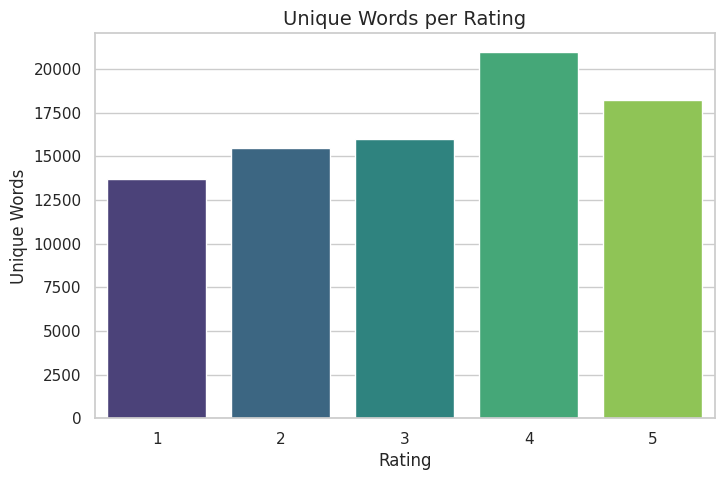

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    x='Rating',
    y='Unique Words',
    data=vocab_df,
    palette='viridis'
)

plt.title("Unique Words per Rating", fontsize=14)
plt.xlabel("Rating")
plt.ylabel("Unique Words")

plt.show()

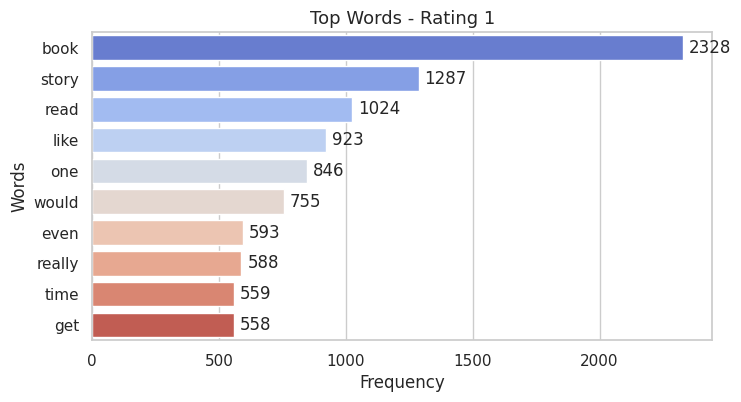

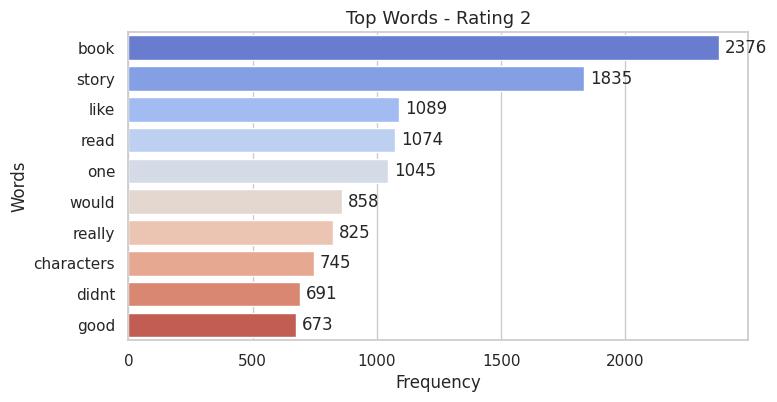

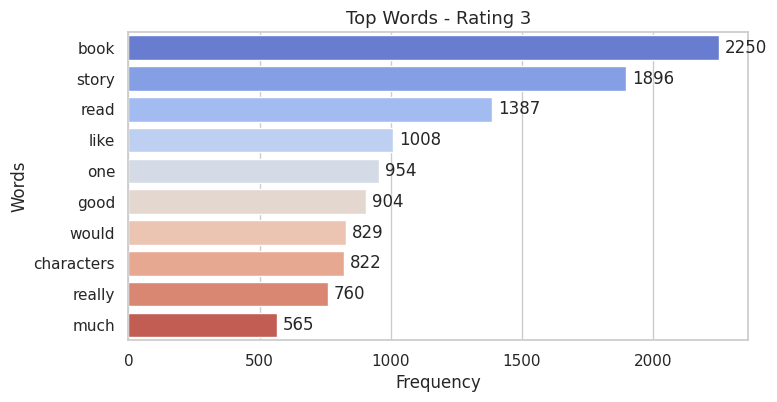

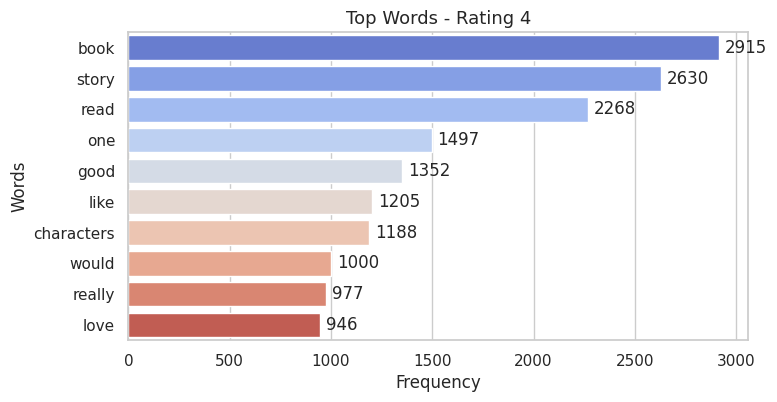

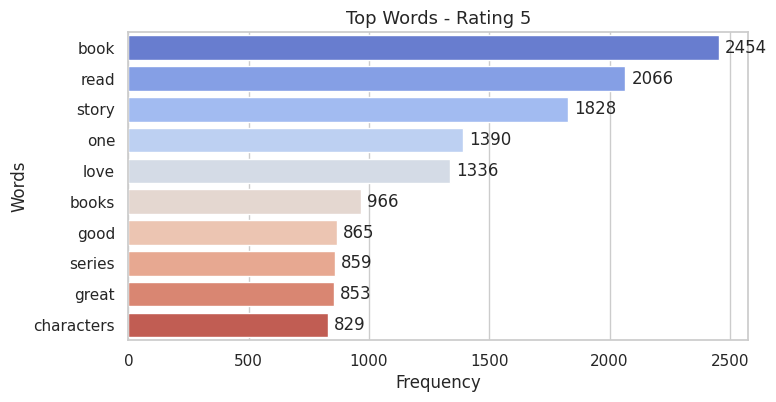

In [ ]:
for rating, group in data_cleaned.groupby('rating'):

    all_words = [w for tokens in group['tokens'] for w in tokens]
    counter = Counter(all_words)
    top10 = counter.most_common(10)

    words = [w for w, _ in top10]
    counts = [c for _, c in top10]

    plt.figure(figsize=(8,4))

    ax = sns.barplot(
        x=counts,
        y=words,
        palette='coolwarm'
    )

    for i, v in enumerate(counts):
        ax.text(v + max(counts)*0.01, i, str(v), va='center')

    plt.title(f"Top Words - Rating {rating}", fontsize=13)
    plt.xlabel("Frequency")
    plt.ylabel("Words")

    plt.show()

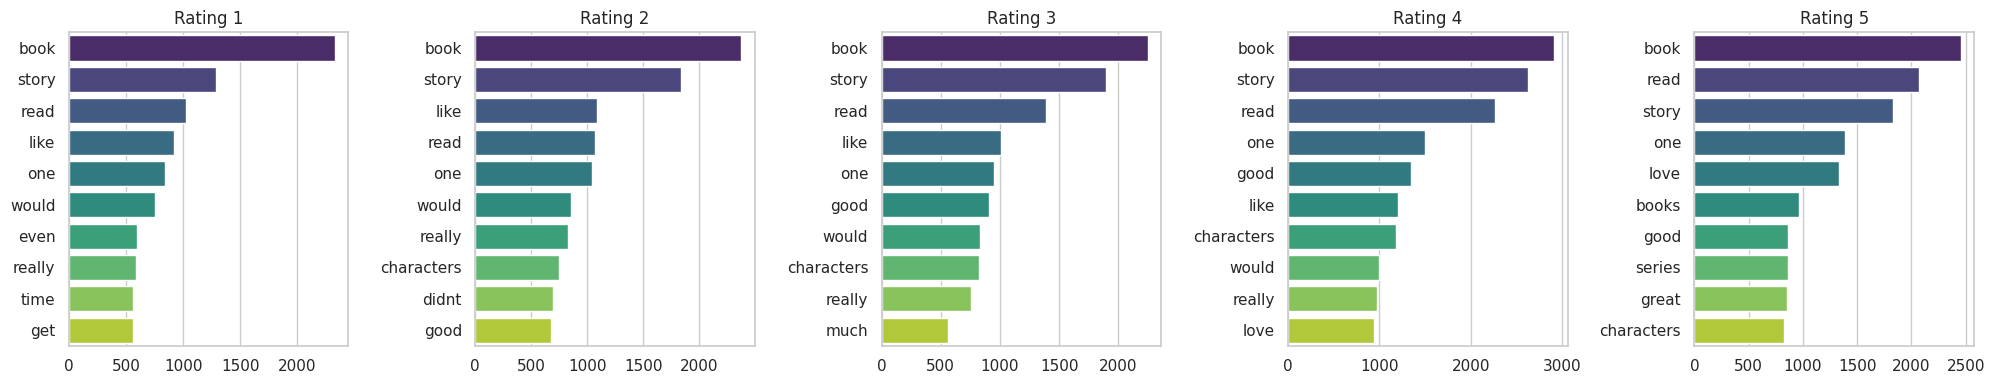

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20,4))

for idx, (rating, group) in enumerate(data_cleaned.groupby('rating')):

    all_words = [w for tokens in group['tokens'] for w in tokens]
    counter = Counter(all_words)
    top10 = counter.most_common(10)

    words = [w for w, _ in top10]
    counts = [c for _, c in top10]

    sns.barplot(
        x=counts,
        y=words,
        ax=axes[idx],
        palette='viridis'
    )

    axes[idx].set_title(f"Rating {rating}")
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel("")

plt.tight_layout()
plt.show()

## Distinctive words on each rating

In [ ]:
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(data_cleaned['reviewText'])

feature_names = tfidf.get_feature_names_out()

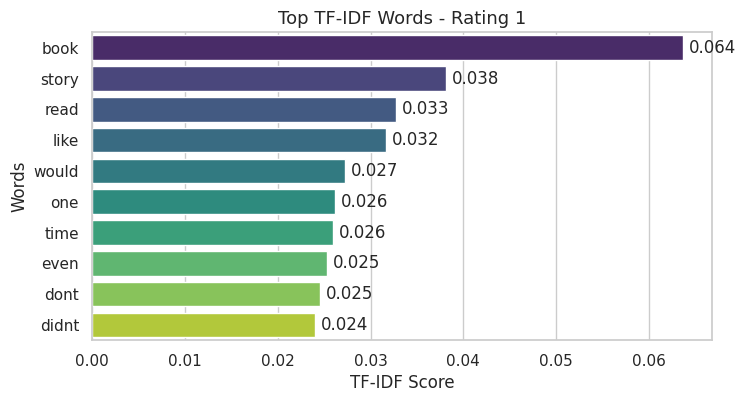

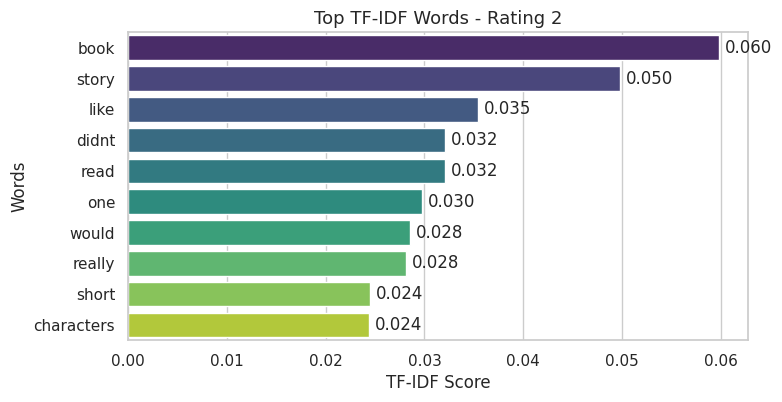

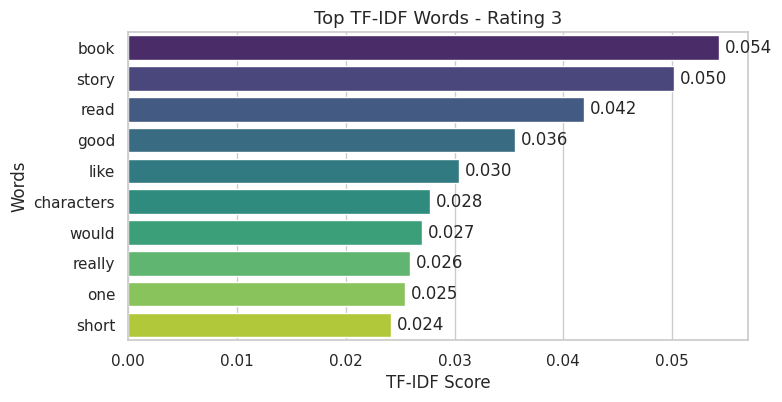

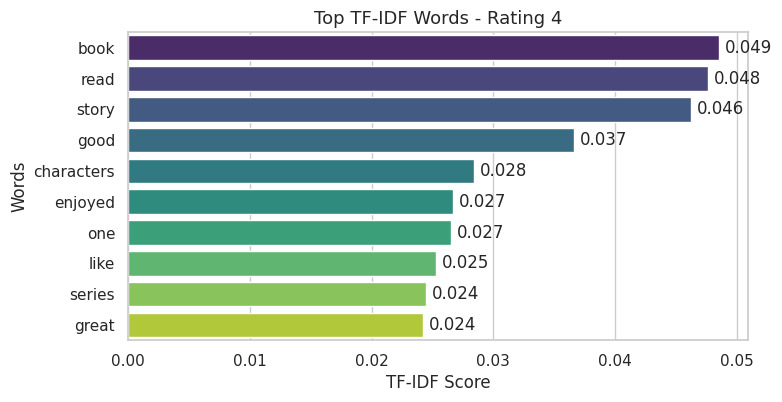

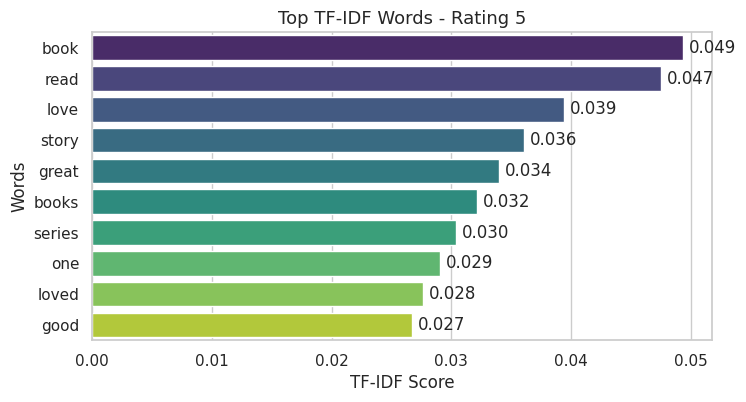

In [ ]:
ratings = sorted(data_cleaned['rating'].unique())

for rating in ratings:

    # lấy index của rating đó
    idx = (data_cleaned['rating'] == rating).values

    # lấy TF-IDF của group
    X_group = X[idx]

    # tính mean score mỗi word
    mean_tfidf = np.asarray(X_group.mean(axis=0)).ravel()

    # lấy top 10
    top_idx = mean_tfidf.argsort()[-10:][::-1]

    top_words = [feature_names[i] for i in top_idx]
    top_scores = mean_tfidf[top_idx]

    # plot
    plt.figure(figsize=(8,4))

    ax = sns.barplot(
        x=top_scores,
        y=top_words,
        palette='viridis'
    )

    # label số
    for i, v in enumerate(top_scores):
        ax.text(v + max(top_scores)*0.01, i, f"{v:.3f}", va='center')

    plt.title(f"Top TF-IDF Words - Rating {rating}", fontsize=13)
    plt.xlabel("TF-IDF Score")
    plt.ylabel("Words")

    plt.show()

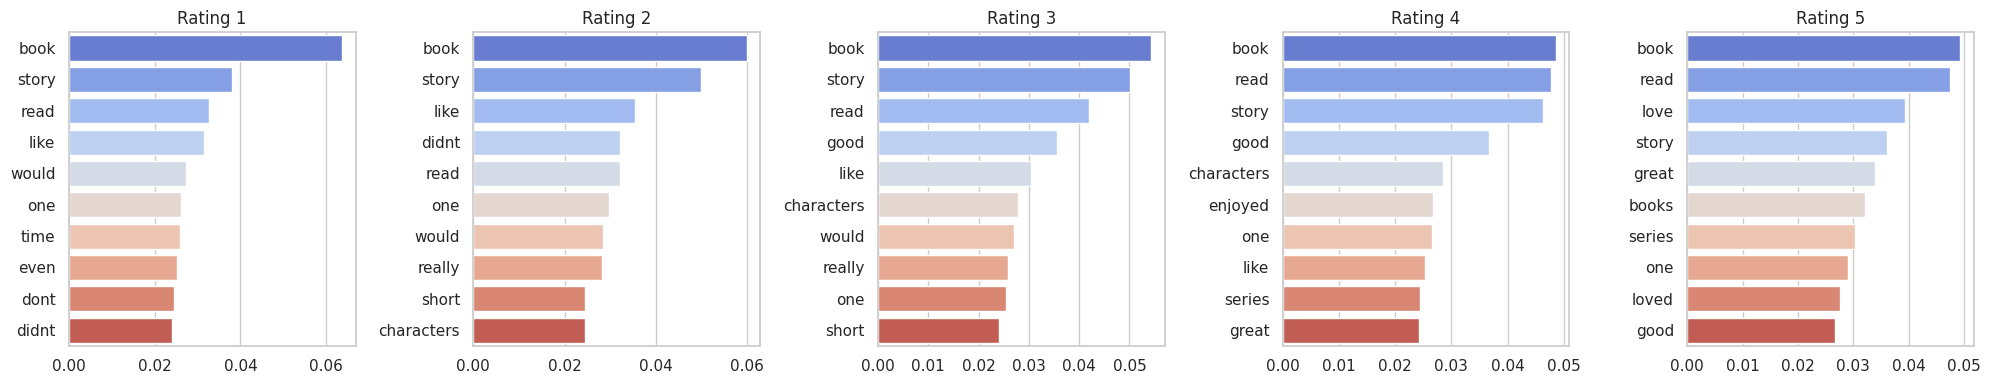

In [ ]:
fig, axes = plt.subplots(1, len(ratings), figsize=(20,4))

for idx_r, rating in enumerate(ratings):

    idx = (data_cleaned['rating'] == rating).values
    X_group = X[idx]

    mean_tfidf = np.asarray(X_group.mean(axis=0)).ravel()
    top_idx = mean_tfidf.argsort()[-10:][::-1]

    top_words = [feature_names[i] for i in top_idx]
    top_scores = mean_tfidf[top_idx]

    sns.barplot(
        x=top_scores,
        y=top_words,
        ax=axes[idx_r],
        palette='coolwarm'
    )

    axes[idx_r].set_title(f"Rating {rating}")
    axes[idx_r].set_xlabel("")
    axes[idx_r].set_ylabel("")

plt.tight_layout()
plt.show()

## N-gram Analysis

In [ ]:
tfidf_ngram = TfidfVectorizer(
    ngram_range=(2,2),   # bigram
    max_features=5000
)

X_ngram = tfidf_ngram.fit_transform(data_cleaned['reviewText'])
feature_names_ngram = tfidf_ngram.get_feature_names_out()

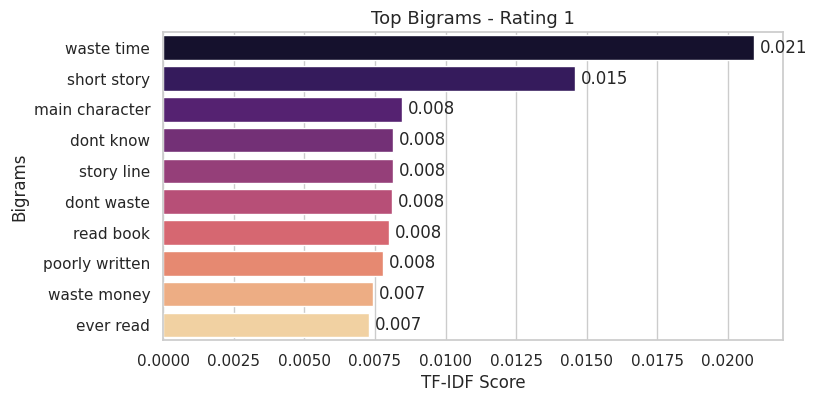

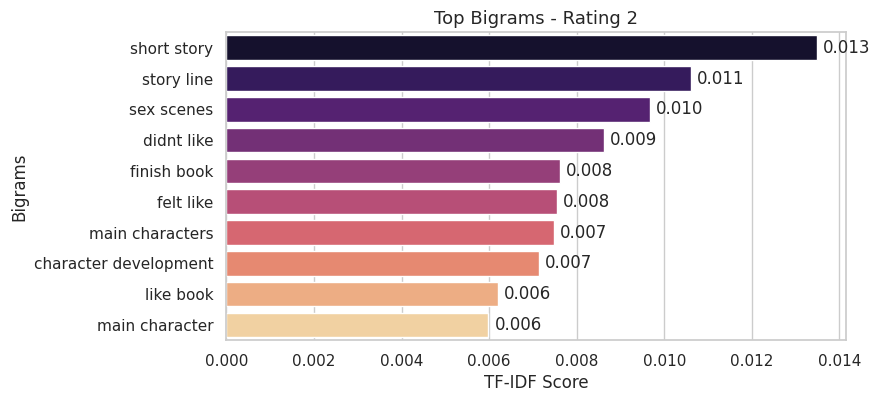

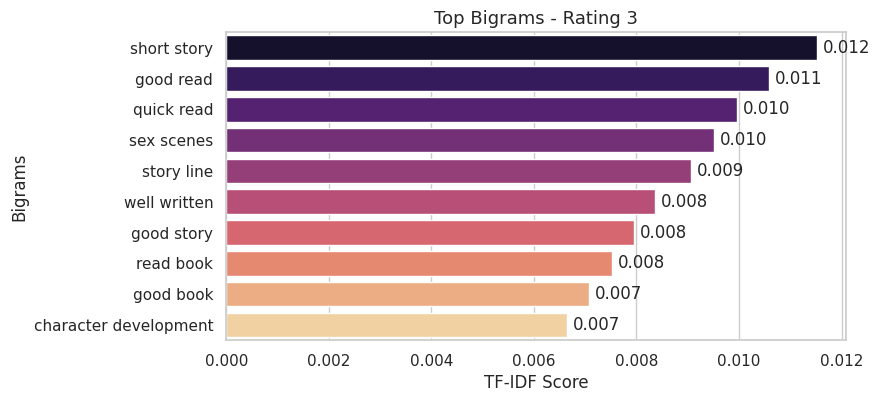

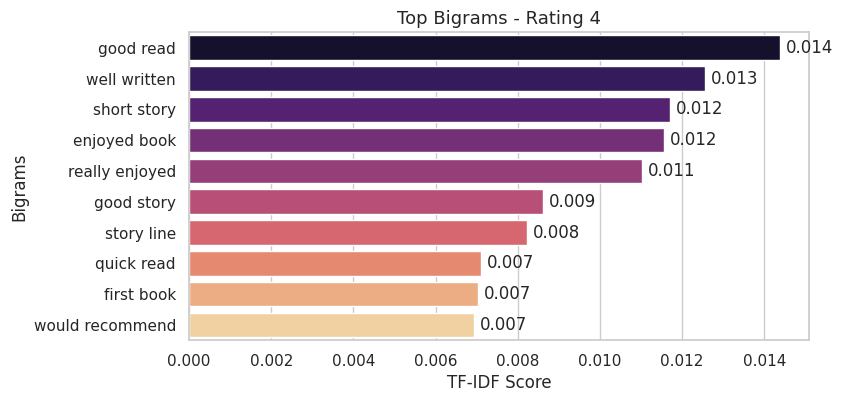

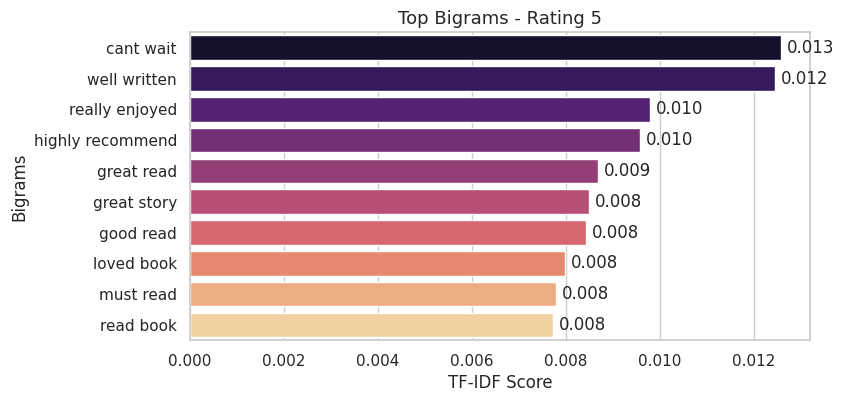

In [ ]:
ratings = sorted(data_cleaned['rating'].unique())

for rating in ratings:

    idx = (data_cleaned['rating'] == rating).values
    X_group = X_ngram[idx]

    mean_tfidf = np.asarray(X_group.mean(axis=0)).ravel()

    top_idx = mean_tfidf.argsort()[-10:][::-1]

    top_ngrams = [feature_names_ngram[i] for i in top_idx]
    top_scores = mean_tfidf[top_idx]

    plt.figure(figsize=(8,4))

    ax = sns.barplot(
        x=top_scores,
        y=top_ngrams,
        palette='magma'
    )

    for i, v in enumerate(top_scores):
        ax.text(v + max(top_scores)*0.01, i, f"{v:.3f}", va='center')

    plt.title(f"Top Bigrams - Rating {rating}", fontsize=13)
    plt.xlabel("TF-IDF Score")
    plt.ylabel("Bigrams")

    plt.show()

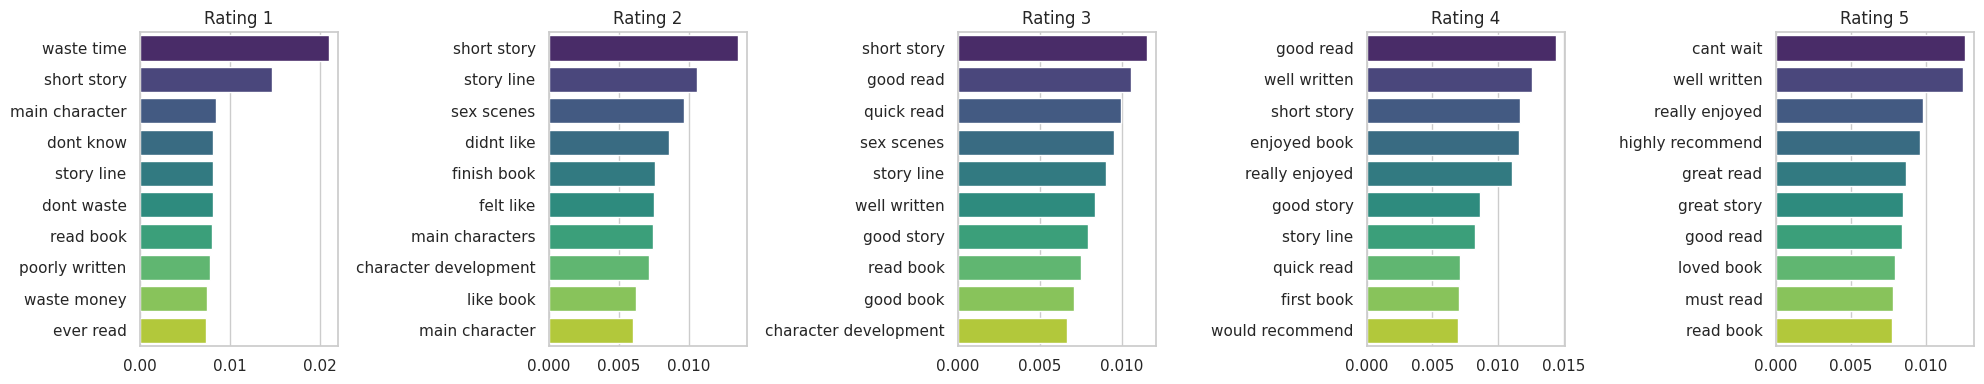

In [ ]:
fig, axes = plt.subplots(1, len(ratings), figsize=(20,4))

for idx_r, rating in enumerate(ratings):

    idx = (data_cleaned['rating'] == rating).values
    X_group = X_ngram[idx]

    mean_tfidf = np.asarray(X_group.mean(axis=0)).ravel()
    top_idx = mean_tfidf.argsort()[-10:][::-1]

    top_ngrams = [feature_names_ngram[i] for i in top_idx]
    top_scores = mean_tfidf[top_idx]

    sns.barplot(
        x=top_scores,
        y=top_ngrams,
        ax=axes[idx_r],
        palette='viridis'
    )

    axes[idx_r].set_title(f"Rating {rating}")
    axes[idx_r].set_xlabel("")
    axes[idx_r].set_ylabel("")

plt.tight_layout()
plt.show()

## Cosine Matrix

In [ ]:
ratings = sorted(data_cleaned['rating'].unique())

sim_matrix = np.zeros((len(ratings), len(ratings)))


for i, r1 in enumerate(ratings):

    idx1 = np.where(data_cleaned['rating'] == r1)[0]
    X1 = X[idx1]

    for j, r2 in enumerate(ratings):
        idx2 = np.where(data_cleaned['rating'] == r2)[0]
        X2 = X[idx2]

        # cosine toàn bộ cặp
        sim = cosine_similarity(X1, X2)

        # lấy trung bình
        sim_matrix[i, j] = sim.mean()

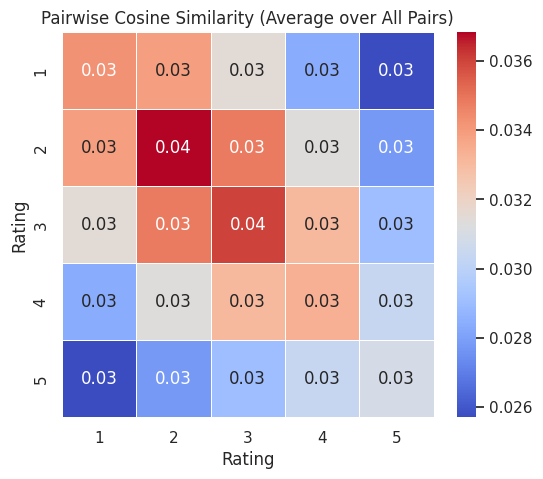

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    xticklabels=ratings,
    yticklabels=ratings,
    linewidths=0.5
)

plt.title("Pairwise Cosine Similarity (Average over All Pairs)")
plt.xlabel("Rating")
plt.ylabel("Rating")

plt.show()

## Visualization

#### Visualize wordcloud for positive comments

In [ ]:
positive_cmt = data_cleaned[data_cleaned.sentiment == 1].reviewText

In [ ]:
positive_cmt = ' '.join(positive_cmt)

In [ ]:
wc = WordCloud().generate(positive_cmt)
wc

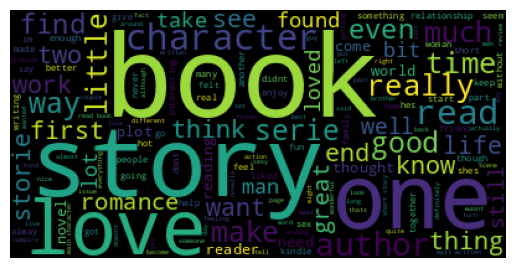

In [ ]:
plt.imshow(wc)
plt.axis('off')
plt.show()

#### Visualize wordcloud for negative comments

In [ ]:
negative_cmt = data_cleaned[data_cleaned.sentiment == 0].reviewText
negative_cmt = ' '.join(negative_cmt)
wc = WordCloud().generate(negative_cmt)
wc

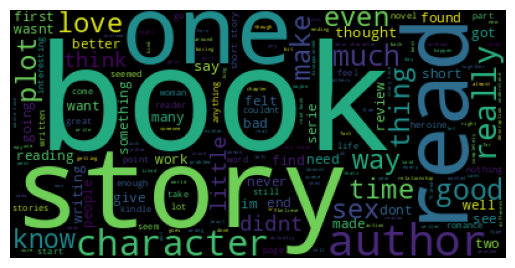

In [ ]:
plt.imshow(wc)
plt.axis('off')
plt.show()

# Asssignment2

## Build model for classification rating - sentiment analysis

We assume that with the rating less than 3 will be labelled as negative, rating 3 is neutral and the other are marked as positive

### Labelling

In [ ]:
data_cleaned['label'] = data_cleaned['rating'].apply(
    lambda x: 'negative' if x < 3 else ('neutral' if x == 3 else 'positive')
)

In [ ]:
data_cleaned['label'].value_counts()

,count
label,
positive,5994
negative,3998
neutral,2000


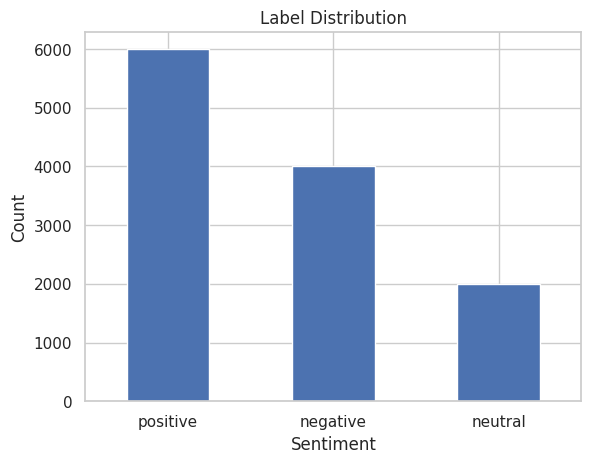

In [ ]:
label_counts = data_cleaned['label'].value_counts()

plt.figure()
label_counts.plot(kind='bar')
plt.title('Label Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

### Divide Data

In [ ]:
label_map = {
    'negative': 0,
    'neutral': 1,
    'positive': 2
}

data_cleaned['label_encoded'] = data_cleaned['label'].map(label_map)

In [ ]:
data_cleaned.columns

Index(['asin', 'helpful', 'rating', 'reviewText', 'reviewTime', 'reviewerID',
       'reviewerName', 'summary', 'unixReviewTime', 'word_count', 'char_count',
       'sentiment', 'tokens', 'label', 'label_encoded'],
      dtype='object')

In [ ]:
X = data_cleaned['reviewText']
y = data_cleaned['label_encoded']

In [ ]:
X_tr, X_test, y_tr, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# X_val, X_test, y_val, y_test = train_test_split(
#     X_temp,
#     y_temp,
#     test_size=0.5,
#     stratify=y_temp,
#     random_state=42
# )

### Traditional Machine Learning

#### Baseline

In [ ]:
word_tfidf = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    max_features=10000,
    min_df=2
)

char_tfidf = TfidfVectorizer(
    analyzer='char',
    ngram_range=(3, 5),
    max_features=20000,
    min_df=2
)

In [ ]:
tfidf = FeatureUnion([
    ('word', word_tfidf),
    ('char', char_tfidf)
])

In [ ]:
X_tr_tfidf = tfidf.fit_transform(X_tr)
X_test_tfidf = tfidf.transform(X_test)

In [ ]:
model = LogisticRegression(
    max_iter=2000,
    C=3,
    n_jobs=-1
)

In [ ]:
scores = cross_val_score(model, X_tr_tfidf, y_tr, cv=5, scoring='accuracy')

print("CV scores:", scores)
print("Mean CV:", scores.mean())

CV scores: [0.73475769 0.74101094 0.74934862 0.74244004 0.73044838]
Mean CV: 0.7396011348020265


In [ ]:
model.fit(X_tr_tfidf, y_tr)

LogisticRegression(C=3, max_iter=2000, n_jobs=-1)

In [ ]:
y_test_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Macro F1:", f1_score(y_test, y_test_pred, average='macro'))

print(classification_report(y_test, y_test_pred))

Accuracy: 0.759899958315965
Macro F1: 0.666844386972695
              precision    recall  f1-score   support

           0       0.78      0.82      0.80       800
           1       0.45      0.30      0.36       400
           2       0.81      0.87      0.84      1199

    accuracy                           0.76      2399
   macro avg       0.68      0.66      0.67      2399
weighted avg       0.74      0.76      0.75      2399



#### Build traditional machine learning

In [ ]:
def plot_baseline_comparison(results):
    df = pd.DataFrame(results)

    # convert
    df["F1 Score (%)"] = df["F1 Score (%)"].astype(float)
    df["Inference (ms/sample)"] = df["Inference (ms/sample)"].astype(float)
    df["RAM (MB)"] = df["RAM (MB)"].astype(float)
    df["Train Time (min)"] = df["Train Time (min)"].astype(float)

    df = df.sort_values("F1 Score (%)", ascending=False)

    models = df["Model Name"]

    colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]

    plt.figure(figsize=(16, 10))

    # ===== F1 =====
    plt.subplot(2, 2, 1)
    bars = plt.bar(models, df["F1 Score (%)"], color=colors)
    plt.title("F1 Score Comparison", fontsize=13, weight='bold')
    plt.ylabel("F1 (%)")
    plt.xticks(rotation=25)

    # highlight best
    best_idx = df["F1 Score (%)"].idxmax()
    bars[list(df.index).index(best_idx)].set_color("#DD8452")

    # ===== INFERENCE =====
    plt.subplot(2, 2, 2)
    plt.bar(models, df["Inference (ms/sample)"], color="#55A868")
    plt.title("Inference Time (ms/sample)", fontsize=13, weight='bold')
    plt.xticks(rotation=25)

    # ===== RAM =====
    plt.subplot(2, 2, 3)
    plt.bar(models, df["RAM (MB)"], color="#C44E52")
    plt.title("RAM Usage (MB)", fontsize=13, weight='bold')
    plt.xticks(rotation=25)

    # ===== TRAIN TIME =====
    plt.subplot(2, 2, 4)
    plt.bar(models, df["Train Time (min)"], color="#8172B2")
    plt.title("Training Time (min)", fontsize=13, weight='bold')
    plt.xticks(rotation=25)

    plt.tight_layout()
    plt.show()

In [ ]:
BASE_DIR = "/content/drive/MyDrive/P4AIDS-Assignment/Text/experiment_ml"
os.makedirs(BASE_DIR, exist_ok=True)

CSV_PATH = os.path.join(BASE_DIR, "baseline_results.csv")

In [ ]:
models = [
    ('LinearSVC', LinearSVC(random_state=SEED)),

    ('LogisticRegression', LogisticRegression(
        random_state=SEED,
        max_iter=1000,
        class_weight='balanced'
    )),

    ('NaiveBayes', MultinomialNB(alpha=1.0)),  #

    ('KNeighborsClassifier', KNeighborsClassifier(
        n_neighbors=5,
        weights='distance',
        metric='cosine'
    )),

    ('RandomForest', RandomForestClassifier(
        random_state=SEED,
        n_jobs=-1,
        class_weight='balanced'
    )),

    ('DecisionTree', DecisionTreeClassifier(
        random_state=SEED,
        max_depth=20,            # tránh overfit
        class_weight='balanced'
    ))
]

In [ ]:

baseline_results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

process = psutil.Process(os.getpid())

for name, model in models:
    print(f"\nTraining: {name}")

    # ====== MEMORY BEFORE ======
    mem_before = process.memory_info().rss / (1024 ** 2)  # MB

    # ====== TRAIN TIME (CV) ======
    start_train = time.time()
    cv_scores = cross_val_score(
        model,
        X_tr_tfidf,
        y_tr,
        cv=cv,
        scoring='f1_macro',
        n_jobs=-1
    )
    train_time = (time.time() - start_train) / 60  # phút

    # ====== FIT 1 MODEL ======
    model_clone = clone(model)
    model_clone.fit(X_tr_tfidf, y_tr)

    # ====== INFERENCE TIME (stable) ======
    repeats = 3
    start_inf = time.time()
    for _ in range(repeats):
        _ = model_clone.predict(X_test_tfidf)

    inf_time = (time.time() - start_inf) / (repeats * X_test_tfidf.shape[0]) * 1000

    # ====== ACCURACY ======
    y_pred = model_clone.predict(X_test_tfidf)
    acc = accuracy_score(y_test, y_pred) * 100

    # ====== MEMORY AFTER ======
    mem_after = process.memory_info().rss / (1024 ** 2)
    memory_used = mem_after  # FIX: không dùng delta

    # ====== SAVE RESULT ======
    row = {
        "Model Name": name,
        "Architecture": "TF-IDF + " + name,
        "Strategy": "classic_ml",
        "Accuracy (%)": f"{acc:.2f}",
        "F1 Score (%)": f"{cv_scores.mean()*100:.2f}",
        "Inference (ms/sample)": f"{inf_time:.4f}",
        "RAM (MB)": f"{memory_used:.1f}",
        "Train Time (min)": f"{train_time:.2f}",
        "Total Params (M)": "-",
        "Trainable Params (M)": "-"
    }

    baseline_results.append(row)

    # ====== SAVE CSV (append) ======
    df_row = pd.DataFrame([row])

    if not os.path.exists(CSV_PATH):
        df_row.to_csv(CSV_PATH, index=False)
    else:
        df_row.to_csv(CSV_PATH, mode='a', header=False, index=False)

    print(f"{name}: Macro F1 = {cv_scores.mean():.4f} (±{cv_scores.std():.4f})")
    print(f" Saved results for {name}")


Training: LinearSVC
LinearSVC: Macro F1 = 0.6290 (±0.0117)
 Saved results for LinearSVC

Training: LogisticRegression
LogisticRegression: Macro F1 = 0.6543 (±0.0079)
 Saved results for LogisticRegression

Training: NaiveBayes
NaiveBayes: Macro F1 = 0.5393 (±0.0057)
 Saved results for NaiveBayes

Training: KNeighborsClassifier
KNeighborsClassifier: Macro F1 = 0.5474 (±0.0038)
 Saved results for KNeighborsClassifier

Training: RandomForest
RandomForest: Macro F1 = 0.5048 (±0.0050)
 Saved results for RandomForest

Training: DecisionTree
DecisionTree: Macro F1 = 0.4697 (±0.0137)
 Saved results for DecisionTree


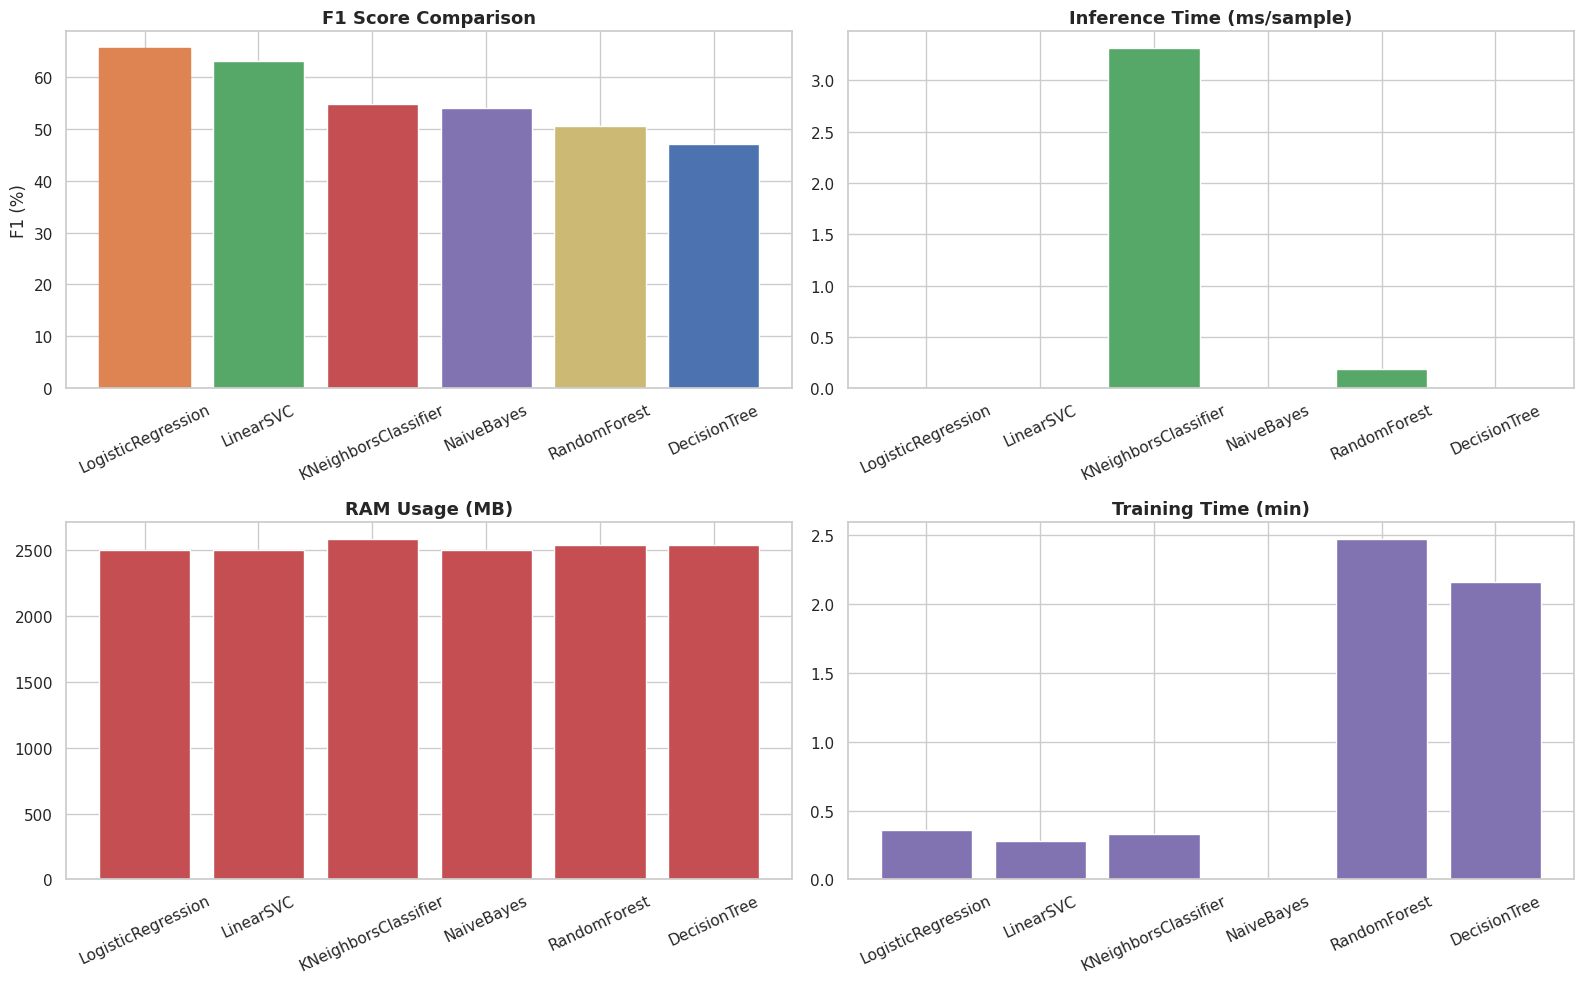

In [ ]:
plot_baseline_comparison(baseline_results)

#### Tuning Params

In [ ]:
models_with_grids = [
    ('LinearSVC', LinearSVC(random_state=SEED), {
        'C': [0.01, 0.1, 1, 10, 100],
        'class_weight': [None, 'balanced']
    }),

    ('LogisticRegression', LogisticRegression(random_state=SEED, max_iter=1000), {
        'C': [0.01, 0.1, 1, 10, 100],
        'penalty': ['l2'],
        'class_weight': [None, 'balanced']
    }),

    ('MultinomialNB', MultinomialNB(), {
        'alpha': [0.01, 0.1, 0.5, 1.0, 2.0]
    }),

    ('KNeighborsClassifier', KNeighborsClassifier(), {
        'n_neighbors': [3, 5, 7, 9, 11, 15],
        'weights': ['uniform', 'distance'],
        'metric': ['cosine', 'euclidean']  #
    }),

    ('RandomForest', RandomForestClassifier(random_state=SEED, n_jobs=-1), {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 10, 20, 30, 50],
        'min_samples_split': [2, 5, 10],
        'class_weight': ['balanced', 'balanced_subsample']
    }),

    ('DecisionTree', DecisionTreeClassifier(random_state=SEED), {
        'criterion': ['gini', 'entropy'],
        'max_depth': [None, 10, 20, 30, 50],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 5],
        'class_weight': [None, 'balanced']
    })
]


In [ ]:
tuned_models = {}
tuning_results = []

for model_name, model, param_grid in models_with_grids:
    print(f"Tuning {model_name}")
    start_time = time.time()

    search = RandomizedSearchCV(
        model, param_grid, n_iter=10, cv=cv,
        scoring='f1_macro', random_state=SEED, n_jobs=-1
    )

    search.fit(X_tr_tfidf, y_tr)

    tuned_models[model_name] = search.best_estimator_
    tuning_results.append({
        'Model': model_name,
        'Best_F1_Macro': search.best_score_,
        'Best_Params': search.best_params_
    })
    print(f" Best F1: {search.best_score_:.4f} | Params: {search.best_params_}")

Tuning LinearSVC
 Best F1: 0.6527 | Params: {'class_weight': 'balanced', 'C': 0.1}
Tuning LogisticRegression
 Best F1: 0.6547 | Params: {'penalty': 'l2', 'class_weight': 'balanced', 'C': 1}
Tuning MultinomialNB
 Best F1: 0.6486 | Params: {'alpha': 0.1}
Tuning KNeighborsClassifier
 Best F1: 0.5501 | Params: {'weights': 'distance', 'n_neighbors': 7, 'metric': 'cosine'}
Tuning RandomForest
 Best F1: 0.5637 | Params: {'n_estimators': 200, 'min_samples_split': 2, 'max_depth': 10, 'class_weight': 'balanced_subsample'}
Tuning DecisionTree
 Best F1: 0.4673 | Params: {'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 10, 'criterion': 'entropy', 'class_weight': 'balanced'}


In [ ]:
tuning_df = pd.DataFrame(tuning_results).sort_values('Best_F1_Macro', ascending=False)
tuning_df.head(6)

,Model,Best_F1_Macro,Best_Params
1,LogisticRegression,0.654687,"{'penalty': 'l2', 'class_weight': 'balanced', ..."
0,LinearSVC,0.652696,"{'class_weight': 'balanced', 'C': 0.1}"
2,MultinomialNB,0.648599,{'alpha': 0.1}
4,RandomForest,0.563663,"{'n_estimators': 200, 'min_samples_split': 2, ..."
3,KNeighborsClassifier,0.550084,"{'weights': 'distance', 'n_neighbors': 7, 'met..."
5,DecisionTree,0.467259,"{'min_samples_split': 5, 'min_samples_leaf': 1..."


#### Boosting algorithm

In [ ]:
# xgb_model = xgb.XGBClassifier(
#     random_state=SEED,
#     eval_metric='mlogloss',
#     max_depth=6,
#     learning_rate=0.1,
#     n_estimators=100
# )

# xgb_scores = cross_val_score(xgb_model, X_tr_tfidf, y_tr, cv=cv, scoring='f1_macro', n_jobs=-1)
# print(f"XGBoost: Macro F1 = {xgb_scores.mean():.4f} (±{xgb_scores.std():.4f})")

# xgb_model.fit(X_tr_tfidf, y_tr)
# tuned_models['XGBoost'] = xgb_model


In [ ]:

best_model_name = tuning_df.iloc[0]['Model']
best_model = tuned_models[best_model_name]

y_pred = best_model.predict(X_test_tfidf)

print("\nCLASSIFICATION REPORT (testIDATION SET):")
print(classification_report(y_test, y_pred, digits=4))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

macro_f1_test = f1_score(y_test, y_pred, average='macro')
print(f"\nFinal Etestuation: {macro_f1_test:.4f}")

### Deep learning - Transformers backbone approach

#### Note

In [ ]:
"""
Pipeline: Pretrained Transformer Encoder for Text Classification

Objective:
Learn a mapping f: text → label (e.g., sentiment: positive/negative/neutral)
using a pretrained Transformer encoder (e.g., BERT, RoBERTa, XLM-RoBERTa).

--------------------------------------------------
I. PRETRAINING (done beforehand)

Self-supervised objective: Masked Language Modeling (MLM)

Given tokenized sequence x = [x1, x2, ..., xn]
Randomly mask positions M ⊂ {1,...,n}

Model learns:
    P(x_i | x_{\setminus i})

Loss:
    L_MLM = - Σ_{i ∈ M} log P(x_i | context)

Where:
- Output logits per token: z_i ∈ R^{|V|}
- Softmax:
    P(x_i = w) = exp(z_i[w]) / Σ_{v ∈ V} exp(z_i[v])

--------------------------------------------------
II. FINETUNING (your task: classification)

INPUT PIPELINE:

raw text
  ↓
Tokenizer (subword: BPE / SentencePiece)
  ↓
input_ids ∈ R^{seq_len}
attention_mask ∈ R^{seq_len}
  ↓
Embedding:
    X ∈ R^{seq_len × d_model}
  ↓
Transformer Encoder:
    H = Transformer(X)
    H ∈ R^{seq_len × d_model}

--------------------------------------------------
III. FEATURE EXTRACTION

Use [CLS] token representation:
    h_cls ∈ R^{d_model}

(or mean pooling over tokens)

--------------------------------------------------
IV. CLASSIFIER HEAD

Linear layer:
    z = W h_cls + b
    W ∈ R^{num_classes × d_model}

Softmax:
    p = softmax(z)

--------------------------------------------------
V. TARGET

Ground truth:
    y ∈ {0,1,...,C-1}

One-hot:
    y_onehot ∈ R^{C}

--------------------------------------------------
VI. LOSS FUNCTION

Cross-entropy:
    L = - Σ_{c=1}^{C} y_c log(p_c)

--------------------------------------------------
VII. FLOW CHART

text
 ↓
subword tokenizer
 ↓
[input_ids, attention_mask]
 ↓
embedding layer
 ↓
transformer encoder (multi-head attention)
 ↓
[CLS] vector
 ↓
linear classifier
 ↓
softmax
 ↓
prediction (label)

--------------------------------------------------
VIII. KEY PROPERTIES

- Contextual embeddings: h_i depends on entire sequence
- Subword tokenization: handles OOV
- Pretrained on large corpora → strong generalization
- End-to-end differentiable

"""
''

''

#### Config

In [ ]:
experiment_configs = [
    {"name": "SciBERT_Freeze", "arch": "allenai/scibert_scivocab_uncased", "tune": "freeze"},
    {"name": "SciBERT_Tuned",  "arch": "allenai/scibert_scivocab_uncased", "tune": "fine_tune"},

    {"name": "ModernBERT_Freeze", "arch": "answerdotai/ModernBERT-base", "tune": "freeze"},
    {"name": "ModernBERT_Tuned",  "arch": "answerdotai/ModernBERT-base", "tune": "fine_tune"},

    {"name": "MiniLM_Freeze", "arch": "MoritzLaurer/multilingual-MiniLMv2-L12-mnli-xnli", "tune": "freeze"},
    {"name": "MiniLM_Tuned",  "arch": "MoritzLaurer/multilingual-MiniLMv2-L12-mnli-xnli", "tune": "fine_tune"},

    {"name": "E5_Freeze", "arch": "intfloat/multilingual-e5-base", "tune": "freeze"},
    {"name": "E5_Tuned",  "arch": "intfloat/multilingual-e5-base", "tune": "fine_tune"},

    # #
    {"name": "XLMR_Freeze", "arch": "xlm-roberta-base", "tune": "freeze"},
    {"name": "XLMR_Tuned",  "arch": "xlm-roberta-base", "tune": "fine_tune"}
]

#### Data preparation

In [ ]:
data_dl = data[df_check_lang == 'en']

In [ ]:
data_dl['label'] = data_dl['rating'].apply(
    lambda x: 'negative' if x < 3 else ('neutral' if x == 3 else 'positive')
)

In [ ]:
label_map = {
    'negative': 0,
    'neutral': 1,
    'positive': 2
}

data_dl['label_encoded'] = data_dl['label'].map(label_map)

In [ ]:
X = data_dl['reviewText']
y = data_dl['label_encoded']

In [ ]:
X_tr, X_temp, y_tr, y_temp = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=42
)

#### Train utils

In [ ]:
def get_tokenizer(model_name):
    return AutoTokenizer.from_pretrained(model_name)

def prepare_dataloaders(tokenizer, batch_size=16, max_len=256):

    train_dataset = TextDataset(X_tr, y_tr, tokenizer, max_len)
    val_dataset   = TextDataset(X_val, y_val, tokenizer, max_len)
    test_dataset  = TextDataset(X_test, y_test, tokenizer, max_len)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, val_loader, test_loader

In [ ]:
def get_scalable_model(model_name, num_classes=3, strategy="freeze"):
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=num_classes
    )

    for param in model.parameters():
        param.requires_grad = False

    if hasattr(model, "classifier"):
        head = model.classifier
    elif hasattr(model, "score"):
        head = model.score
    elif hasattr(model, "classifier_head"):
        head = model.classifier_head
    else:
        raise ValueError(f"Unknown classifier head in {model_name}")

    for param in head.parameters():
        param.requires_grad = True

    if strategy == "fine_tune":

        base = model.base_model

        if hasattr(base, "encoder") and hasattr(base.encoder, "layer"):
            layers = base.encoder.layer

        elif hasattr(base, "layers"):
            layers = base.layers

        elif hasattr(base, "transformer") and hasattr(base.transformer, "layer"):
            layers = base.transformer.layer

        elif hasattr(base, "encoder") and hasattr(base.encoder, "layers"):
            layers = base.encoder.layers

        else:
            raise ValueError(f"Unknown backbone structure for {model_name}")

        for layer in layers[-1:]:
            for param in layer.parameters():
                param.requires_grad = True

    return model

In [ ]:
class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts.tolist()
        self.labels = labels.tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch in loader:  #  inputs → batch
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        outputs = model(   #  forward
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss              #
        logits = outputs.logits          #

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)  #  inputs → labels

        _, predicted = logits.max(1)   #  outputs → logits
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return running_loss / total, 100. * correct / total

In [ ]:
def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch in loader:  #
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(   #
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            logits = outputs.logits

            running_loss += loss.item() * labels.size(0)

            _, predicted = logits.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    return running_loss / total, 100. * correct / total

In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, device, num_epochs=10, model_name="model"):
    since = time.time()

    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': []
    }

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    # ===== ADD: early stopping =====
    best_val_loss = float("inf")
    patience = 2
    patience_counter = 0
    # ===============================

    print(f"Starting training on {device}...")
    print("-" * 30)

    for epoch in range(num_epochs):

        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)

        val_loss, val_acc = validate(model, val_loader, criterion, device)

        if scheduler is not None:
            scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch+1}/{num_epochs}:")
        print(f"  Train Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
        print(f"  Val Loss:   {val_loss:.4f} | Acc: {val_acc:.2f}%")

        # ===== GIỮ NGUYÊN: save best theo acc =====
        if val_acc > best_acc:
            best_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(best_model_wts, f"{model_name}.pth")
            print(f"Saving weights...")

        # ===== ADD: EARLY STOPPING (theo val_loss) =====
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
        else:
            patience_counter += 1
            print(f"No improvement (val_loss). Patience: {patience_counter}/{patience}")

            if patience_counter >= patience:
                print("Early stopping triggered!")
                break
        # =================================================

    time_elapsed = time.time() - since
    print("-" * 30)
    print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best Val Acc: {best_acc:4f}%")

    model.load_state_dict(best_model_wts)
    return model, history

#### Visualization utils

In [ ]:
def evaluate_comprehensive(model, loader, device):
    model.eval()
    all_preds = []
    all_labels = []

    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()

    start_time = time.time()

    with torch.no_grad():
      for batch in loader:

          if isinstance(batch, dict):
              inputs = batch['input_ids'].to(device)
              labels = batch['labels'].to(device)
              outputs = model(input_ids=inputs, labels=None).logits
          else:
              inputs, labels = batch
              inputs, labels = inputs.to(device), labels.to(device)
              outputs = model(inputs)

          _, preds = torch.max(outputs, 1)

          all_preds.extend(preds.cpu().numpy())
          all_labels.extend(labels.cpu().numpy())

    total_time = time.time() - start_time
    inf_time_ms = (total_time / len(loader.dataset)) * 1000
    max_mem = torch.cuda.max_memory_allocated(device) / (1024**2) if device.type == 'cuda' else 0

    acc = accuracy_score(all_labels, all_preds) * 100
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average='weighted'
    )

    return {
        "acc": acc,
        "f1": f1 * 100,
        "inf_time": inf_time_ms,
        "memory": max_mem,
        "cm": confusion_matrix(all_labels, all_preds)
    }

In [ ]:
def plot_styled_confusion_matrix(cm, classes, model_name="Model"):
    plt.figure(figsize=(12, 10))

    # Vẽ heatmap với màu sắc 'Blues' hoặc 'Viridis'
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes,
                annot_kws={"size": 12}, cbar_kws={'label': 'Number of Samples'})

    plt.title(f'Confusion Matrix: {model_name}', fontsize=16, fontweight='bold', pad=20)
    plt.ylabel('Actual Class (Ground Truth)', fontsize=13, fontweight='bold')
    plt.xlabel('Predicted Class', fontsize=13, fontweight='bold')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

In [ ]:
def count_parameters(model):
    # Tổng tham số và tham số đang được train (trainable)
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total_params / 1e6, trainable_params / 1e6  # Đơn vị: Triệu (Millions)

import matplotlib.pyplot as plt
import seaborn as sns

def plot_comparisons(df):
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 3, figsize=(20, 10))

    # 1. Accuracy
    sns.barplot(
        x="Model Name", y="Accuracy (%)", data=df,
        palette="viridis", ax=axes[0, 0]
    )
    axes[0, 0].set_title("Accuracy (%)")
    axes[0, 0].tick_params(axis='x', rotation=30)

    # 2. F1 Score
    sns.barplot(
        x="Model Name", y="F1 Score (%)", data=df,
        palette="crest", ax=axes[0, 1]
    )
    axes[0, 1].set_title("F1 Score (%)")
    axes[0, 1].tick_params(axis='x', rotation=30)

    # 3. Train Time
    sns.barplot(
        x="Model Name", y="Train Time (min)", data=df,
        palette="magma", ax=axes[0, 2]
    )
    axes[0, 2].set_title("Training Time (min)")
    axes[0, 2].tick_params(axis='x', rotation=30)

    # 4. Inference Time
    sns.barplot(
        x="Model Name", y="Inference (ms/sample)", data=df,
        palette="rocket", ax=axes[1, 0]
    )
    axes[1, 0].set_title("Inference Time (ms/sample)")
    axes[1, 0].tick_params(axis='x', rotation=30)

    # 5. VRAM
    sns.barplot(
        x="Model Name", y="VRAM (MB)", data=df,
        palette="coolwarm", ax=axes[1, 1]
    )
    axes[1, 1].set_title("VRAM Usage (MB)")
    axes[1, 1].tick_params(axis='x', rotation=30)

    # 6. Parameters
    sns.barplot(
        x="Model Name", y="Total Params (M)", data=df,
        palette="flare", ax=axes[1, 2]
    )
    axes[1, 2].set_title("Total Parameters (Millions)")
    axes[1, 2].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_all_histories(all_histories):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    for model_name, hist in all_histories.items():
        epochs = range(1, len(hist['train_acc']) + 1)
        # Vẽ Accuracy
        ax1.plot(epochs, hist['val_acc'], label=f'{model_name} (Val)')
        # Vẽ Loss
        ax2.plot(epochs, hist['val_loss'], label=f'{model_name} (Val)')

    ax1.set_title('Validation Accuracy Comparison')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Accuracy (%)')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    ax2.set_title('Validation Loss Comparison')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Loss')
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.tight_layout()
    plt.show()

In [ ]:
def get_best_model_by_f1(df):
    df_temp = df.copy()

    # 1. Clean + convert F1
    df_temp['F1 Score (%)'] = (
        df_temp['F1 Score (%)']
        .astype(str)
        .str.replace('%', '')
        .str.strip()
    )
    df_temp['F1 Score (%)'] = pd.to_numeric(df_temp['F1 Score (%)'], errors='coerce')

    # 2. Drop NaN
    df_temp = df_temp.dropna(subset=['F1 Score (%)'])

    # 3. Lấy row có F1 cao nhất (cách an toàn nhất)
    best_model = df_temp.loc[df_temp['F1 Score (%)'].idxmax()]

    # 4. Print
    print(f"Best Model based on F1-Score: {best_model['Model Name']}")
    print(f"F1-Score: {best_model['F1 Score (%)']:.2f}%")
    print(f"Architecture: {best_model['Architecture']}")

    return best_model

#### Training models

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
BASE_DIR = "/content/drive/MyDrive/P4AIDS-Assignment/Text/experiments"
os.makedirs(BASE_DIR, exist_ok=True)

CSV_PATH = os.path.join(BASE_DIR, "results.csv")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
HIST_DIR = os.path.join(BASE_DIR, "histories")
CM_DIR = os.path.join(BASE_DIR, "confusion_matrices")

os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(HIST_DIR, exist_ok=True)
os.makedirs(CM_DIR, exist_ok=True)

In [ ]:
final_results = []
all_histories = {}
all_confusion_matrices = {}

criterion = None

for cfg in experiment_configs:
    print(f"\n Training: {cfg['name']}")

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    model_name = cfg['name']  #

    tokenizer = get_tokenizer(cfg['arch'])

    train_loader, val_loader, test_loader = prepare_dataloaders(
        tokenizer,
        batch_size=16,
        max_len=256
    )

    model = get_scalable_model(
        cfg['arch'],
        num_classes=3,
        strategy=cfg['tune']
    ).to(device)

    if "deberta" in cfg['arch'].lower():
        lr = 1e-5 if cfg['tune'] == "fine_tune" else 5e-4
    else:
        lr = 2e-5 if cfg['tune'] == "fine_tune" else 1e-3

    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()), lr=lr
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.1, patience=2
    )

    start_train = time.time()
    model, history = train_model(
        model, train_loader, val_loader, criterion,
        optimizer, scheduler, device, num_epochs=10
    )
    train_duration = (time.time() - start_train) / 60

    metrics = evaluate_comprehensive(model, test_loader, device)
    all_confusion_matrices[cfg['name']] = metrics['cm']
    all_histories[cfg['name']] = history

    total_p, train_p = count_parameters(model)

    final_results.append({
        "Model Name": cfg["name"],
        "Architecture": cfg["arch"],
        "Strategy": cfg["tune"],
        "Accuracy (%)": f"{metrics['acc']:.2f}",
        "F1 Score (%)": f"{metrics['f1']:.2f}",
        "Inference (ms/sample)": f"{metrics['inf_time']:.2f}",
        "VRAM (MB)": f"{metrics['memory']:.1f}",
        "Train Time (min)": f"{train_duration:.1f}",
        "Total Params (M)": f"{total_p:.2f}",
        "Trainable Params (M)": f"{train_p:.2f}"
    })

    # ====== ADD: SAVE AFTER EACH CONFIG ======

    # 1. SAVE CSV (append từng dòng)
    df_row = pd.DataFrame([final_results[-1]])

    if not os.path.exists(CSV_PATH):
        df_row.to_csv(CSV_PATH, index=False)
    else:
        df_row.to_csv(CSV_PATH, mode='a', header=False, index=False)

    # 2. SAVE MODEL CHECKPOINT
    ckpt_path = os.path.join(CKPT_DIR, f"{model_name}.pt")
    torch.save({
        'model_state_dict': model.state_dict(),
        'config': cfg,
        'metrics': metrics
    }, ckpt_path)

    # 3. SAVE TRAINING HISTORY
    hist_path = os.path.join(HIST_DIR, f"{model_name}_history.pt")
    torch.save(history, hist_path)

    # 4. SAVE CONFUSION MATRIX
    cm_path = os.path.join(CM_DIR, f"{model_name}_cm.pt")
    torch.save(metrics['cm'], cm_path)

    print(f" Saved everything for {model_name}")


 Training: SciBERT_Freeze


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/442M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting training on cuda...
------------------------------
Epoch 1/10:
  Train Loss: 0.8864 | Acc: 61.12%
  Val Loss:   0.7157 | Acc: 73.56%
Saving weights...
Epoch 2/10:
  Train Loss: 0.7915 | Acc: 66.93%
  Val Loss:   0.7194 | Acc: 69.39%
No improvement (val_loss). Patience: 1/2
Epoch 3/10:
  Train Loss: 0.7544 | Acc: 69.18%
  Val Loss:   0.7404 | Acc: 66.97%
No improvement (val_loss). Patience: 2/2
Early stopping triggered!
------------------------------
Training complete in 9m 10s
Best Val Acc: 73.561301%
 Saved everything for XLMR_Freeze

 Training: XLMR_Tuned


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting training on cuda...
------------------------------
Epoch 1/10:
  Train Loss: 0.7631 | Acc: 67.54%
  Val Loss:   0.5715 | Acc: 76.73%
Saving weights...
Epoch 2/10:
  Train Loss: 0.6130 | Acc: 75.78%
  Val Loss:   0.5760 | Acc: 77.48%
Saving weights...
No improvement (val_loss). Patience: 1/2
Epoch 3/10:
  Train Loss: 0.5753 | Acc: 77.38%
  Val Loss:   0.5777 | Acc: 77.31%
No improvement (val_loss). Patience: 2/2
Early stopping triggered!
------------------------------
Training complete in 10m 31s
Best Val Acc: 77.481234%
 Saved everything for XLMR_Tuned


#### Evaluation

In [ ]:
df_comparison = pd.DataFrame(final_results)
display(df_comparison)

df_comparison.to_csv("model_comparison_results.csv", index=False)

,Model Name,Architecture,Strategy,Accuracy (%),F1 Score (%),Inference (ms/sample),VRAM (MB),Train Time (min),Total Params (M),Trainable Params (M)
0,SciBERT_Freeze,allenai/scibert_scivocab_uncased,freeze,48.75,45.34,16.84,570.1,31.5,109.92,0.00
1,SciBERT_Tuned,allenai/scibert_scivocab_uncased,fine_tune,55.25,45.35,16.87,654.0,32.2,109.92,7.09
2,ModernBERT_Freeze,answerdotai/ModernBERT-base,freeze,59.58,53.33,25.76,723.7,33.2,149.61,0.00
3,ModernBERT_Tuned,answerdotai/ModernBERT-base,fine_tune,58.92,51.23,26.67,778.9,50.9,149.61,5.02
4,MiniLM_Freeze,MoritzLaurer/multilingual-MiniLMv2-L12-mnli-xnli,freeze,44.92,39.42,5.25,542.6,11.8,117.64,0.15
5,MiniLM_Tuned,MoritzLaurer/multilingual-MiniLMv2-L12-mnli-xnli,fine_tune,50.25,46.30,5.08,556.3,9.9,117.64,1.92
6,E5_Freeze,intfloat/multilingual-e5-base,freeze,64.92,61.13,15.10,1219.8,18.5,278.05,0.59
7,E5_Tuned,intfloat/multilingual-e5-base,fine_tune,69.25,66.16,15.17,1301.5,14.6,278.05,7.68
8,XLMR_Freeze,xlm-roberta-base,freeze,54.08,48.78,15.12,1222.1,9.2,278.05,0.59
9,XLMR_Tuned,xlm-roberta-base,fine_tune,57.75,50.78,15.17,1302.5,10.5,278.05,7.68


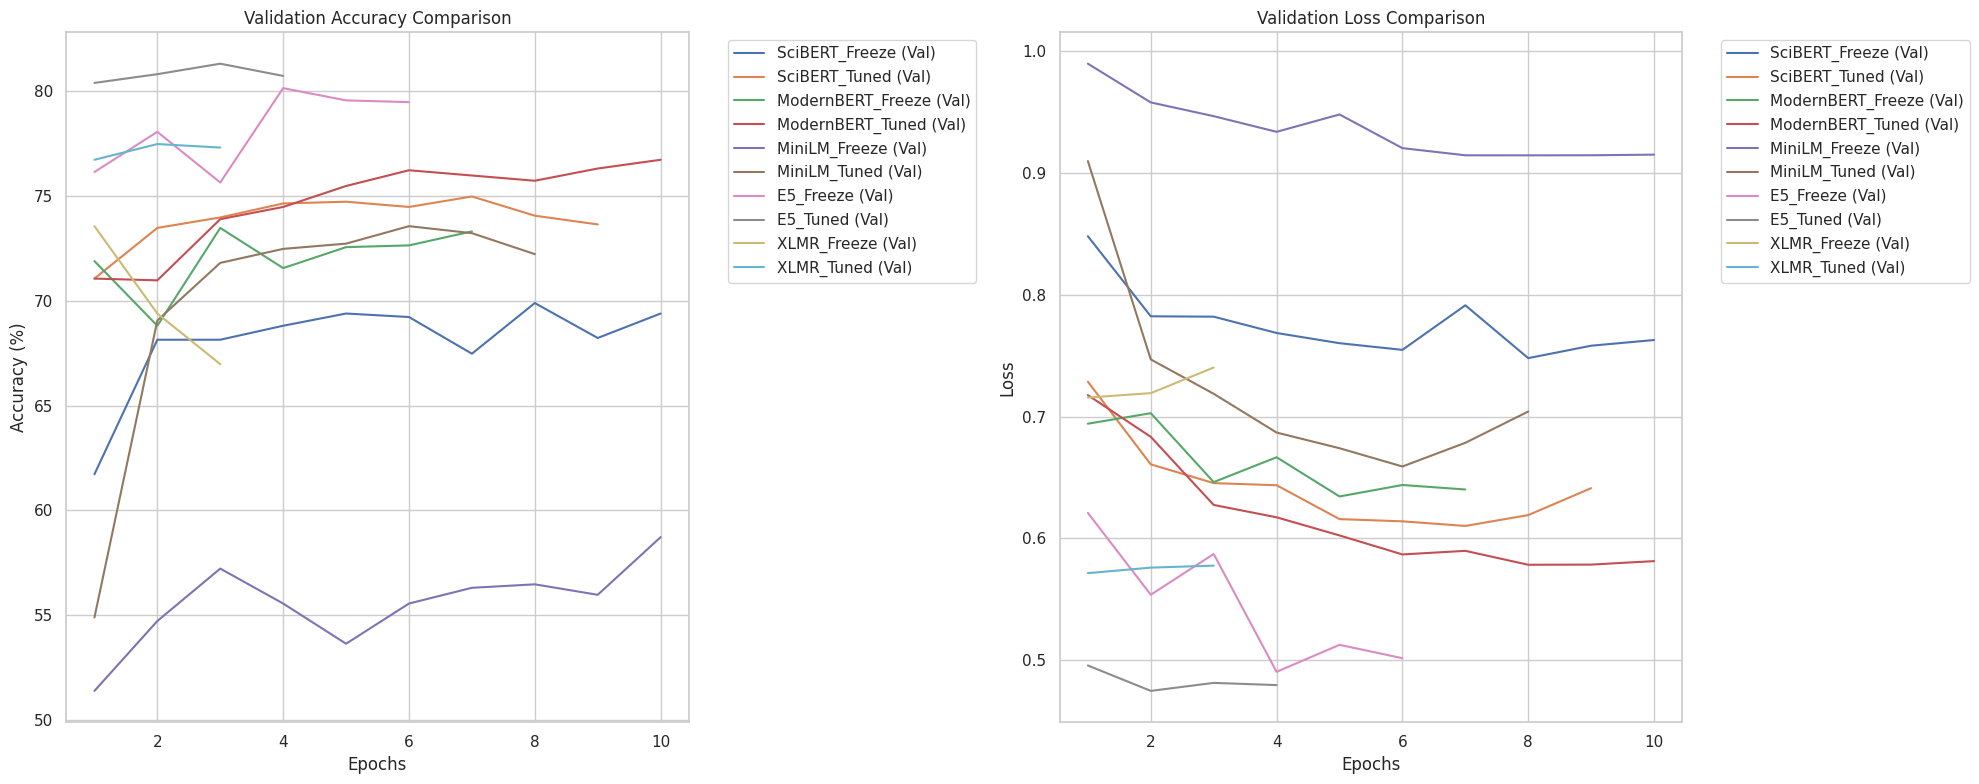

In [ ]:
plot_all_histories(all_histories)

In [ ]:
numeric_cols = [
    "Accuracy (%)",
    "F1 Score (%)",
    "Inference (ms/sample)",
    "VRAM (MB)",
    "Train Time (min)",
    "Total Params (M)",
    "Trainable Params (M)"
]

for col in numeric_cols:
    df_comparison[col] = (
        df_comparison[col]
        .astype(str)                 # phòng trường hợp mixed type
        .str.replace(",", "")       # bỏ dấu phẩy nếu có
        .str.replace("%", "")       # bỏ % nếu lỡ có
        .str.strip()                # bỏ khoảng trắng
    )
    df_comparison[col] = pd.to_numeric(df_comparison[col], errors="coerce")  # convert sang float

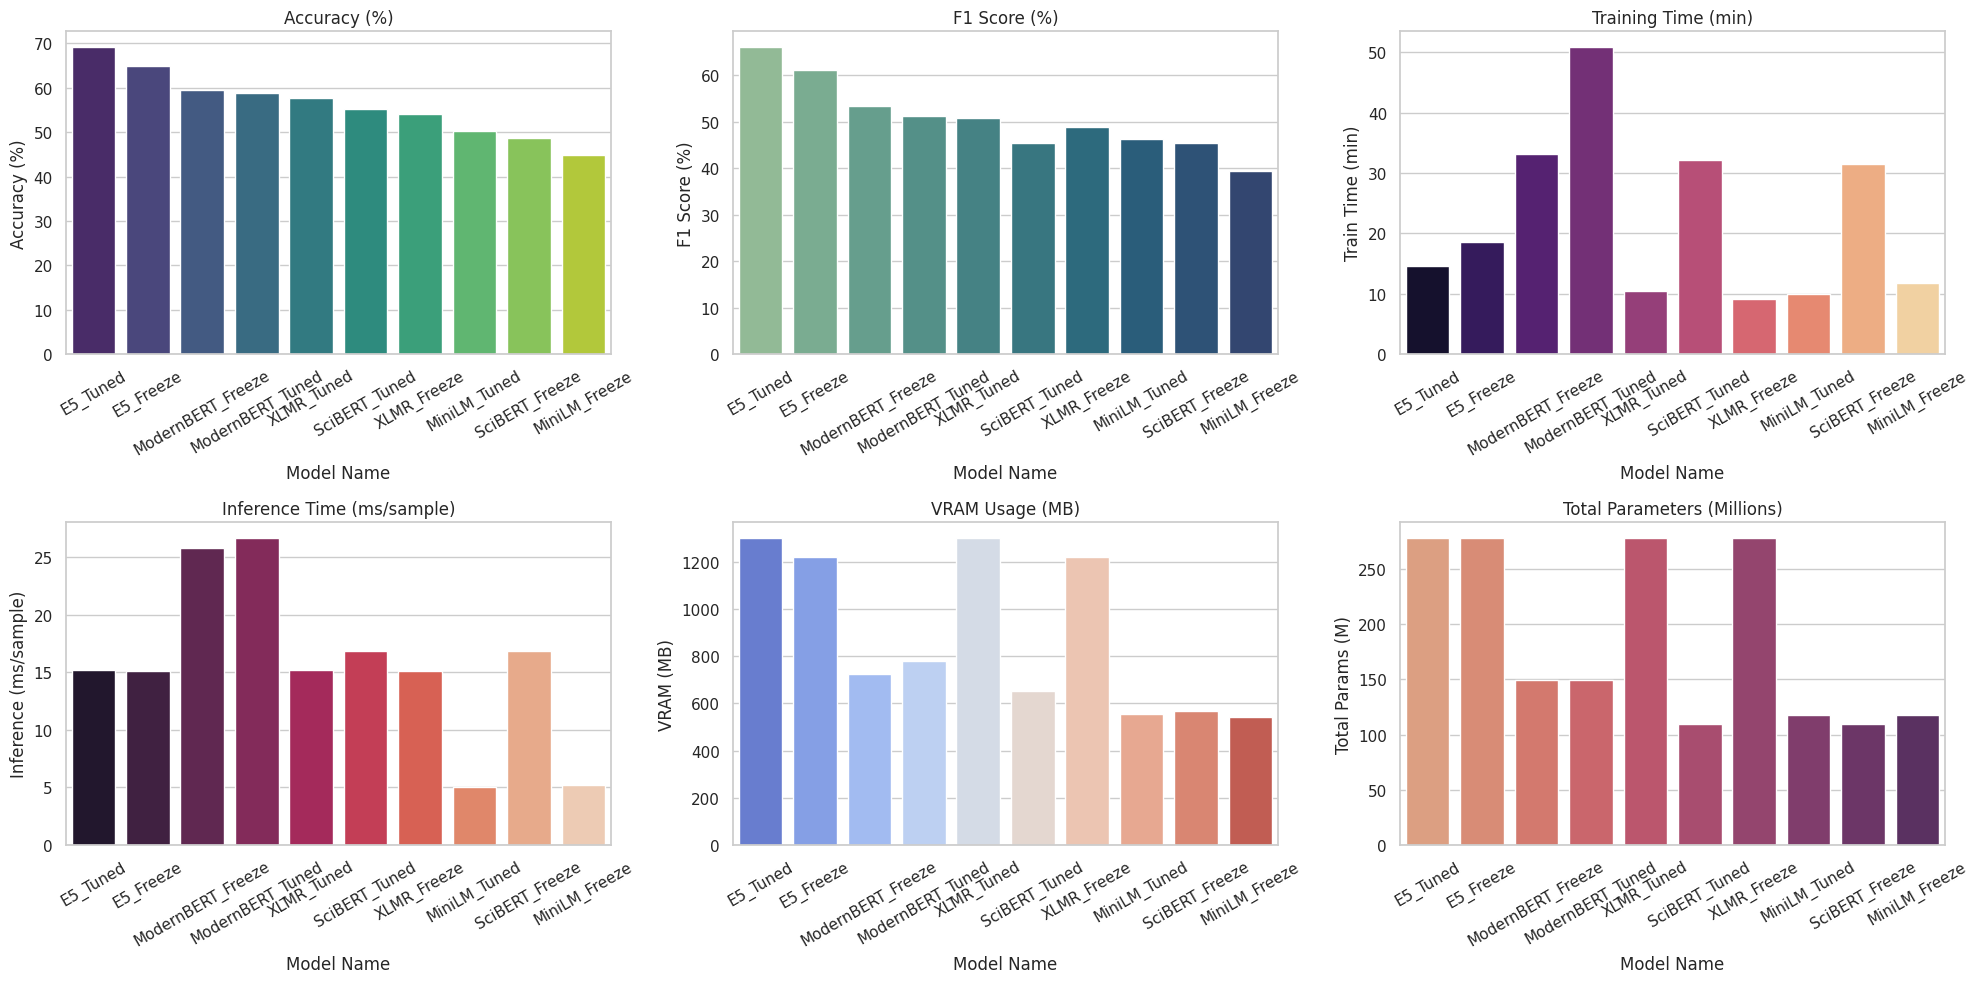

In [ ]:
plot_comparisons(df_comparison)

In [ ]:
best_row = get_best_model_by_f1(df_comparison)
best_model_name = best_row['Model Name']
display(best_row.to_frame().T)

Best Model based on F1-Score: E5_Tuned
F1-Score: 66.16%
Architecture: intfloat/multilingual-e5-base


,Model Name,Architecture,Strategy,Accuracy (%),F1 Score (%),Inference (ms/sample),VRAM (MB),Train Time (min),Total Params (M),Trainable Params (M)
7,E5_Tuned,intfloat/multilingual-e5-base,fine_tune,69.25,66.16,15.17,1301.5,14.6,278.05,7.68


In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ====== PATH ======
BASE_DIR = "/content/drive/MyDrive/P4AIDS-Assignment/Text/experiments"
CM_DIR = os.path.join(BASE_DIR, "confusion_matrices")

# ====== LOAD ALL CM ======
all_cms = {}

for file in os.listdir(CM_DIR):
    if file.endswith("_cm.pt"):
        model_name = file.replace("_cm.pt", "")
        path = os.path.join(CM_DIR, file)

        cm = torch.load(path, weights_only=False)

        # đảm bảo về numpy
        if isinstance(cm, torch.Tensor):
            cm = cm.cpu().numpy()

        all_cms[model_name] = cm

print("Loaded models:", list(all_cms.keys()))

Loaded models: ['SciBERT_Freeze', 'SciBERT_Tuned', 'ModernBERT_Freeze', 'ModernBERT_Tuned', 'MiniLM_Freeze', 'MiniLM_Tuned', 'E5_Freeze', 'E5_Tuned', 'XLMR_Freeze', 'XLMR_Tuned']


In [ ]:
def plot_confusion_matrix(cm, title, class_names=None, normalize=False, save_path=None):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(6,5))

    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f" if normalize else "d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300)

    plt.show()

In [ ]:
class_names = ["Class 0", "Class 1", "Class 2"]

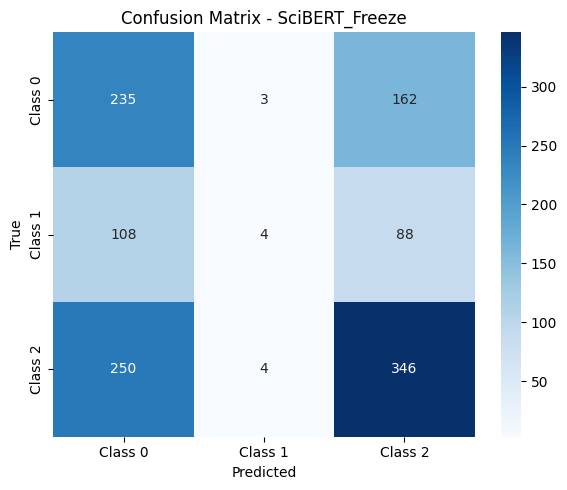

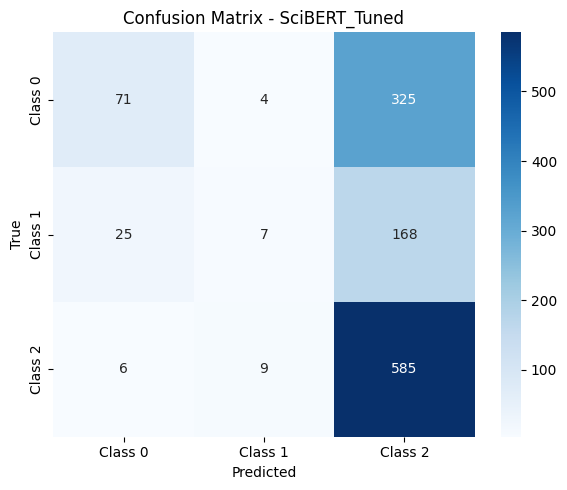

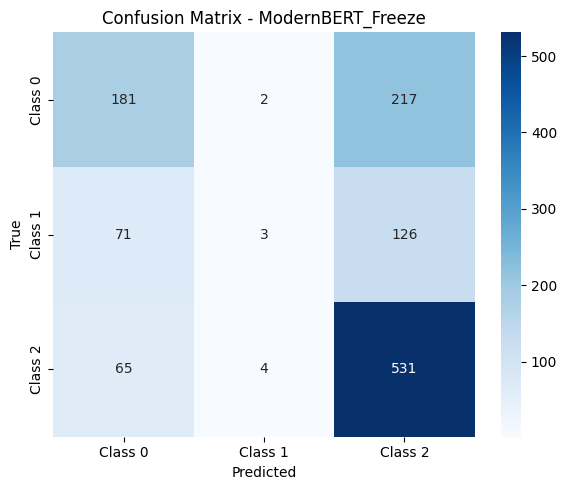

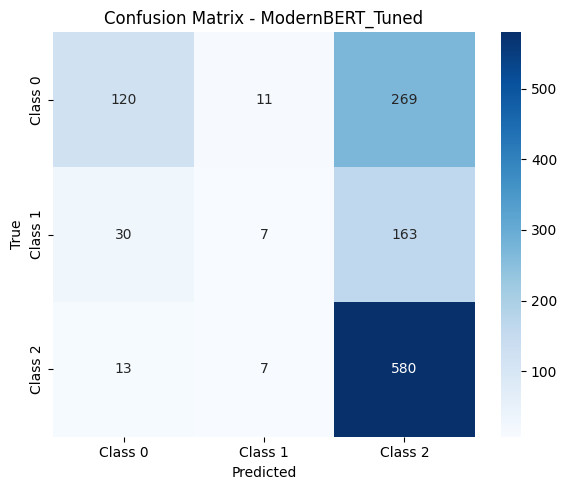

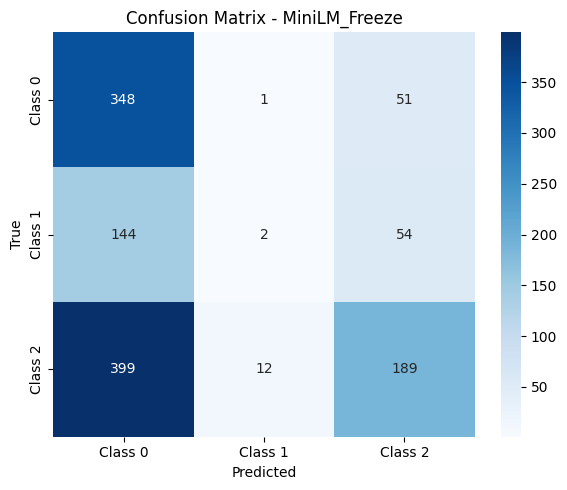

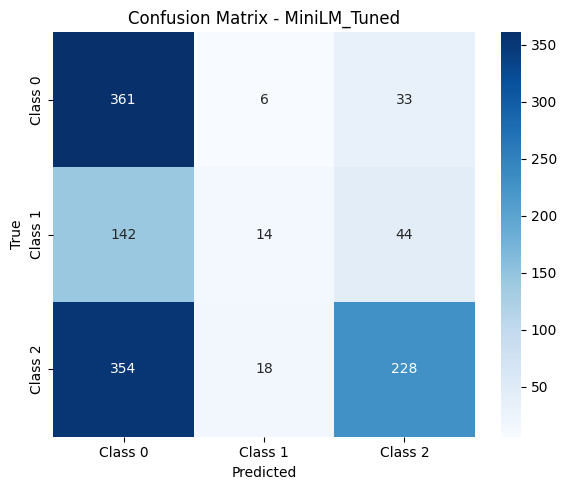

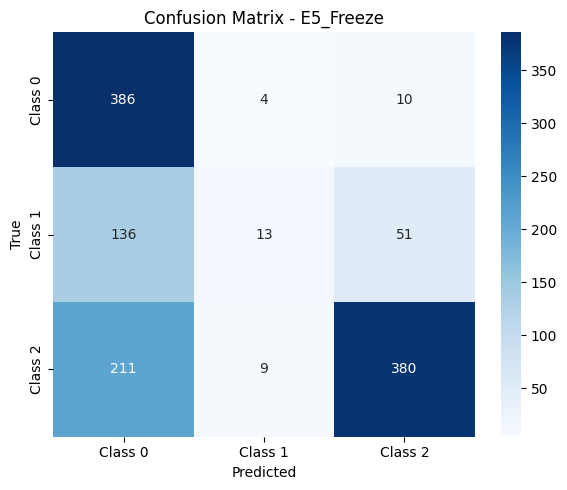

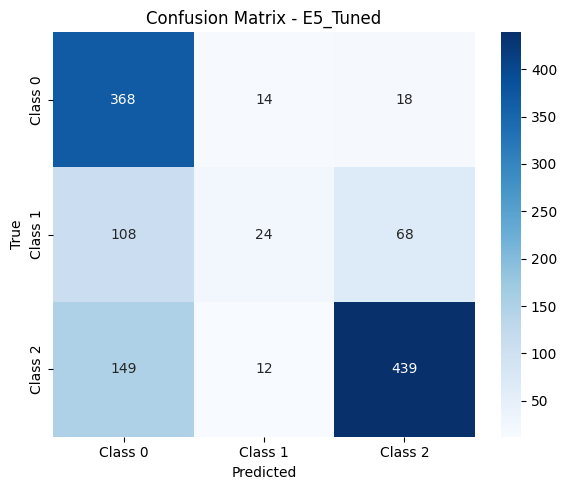

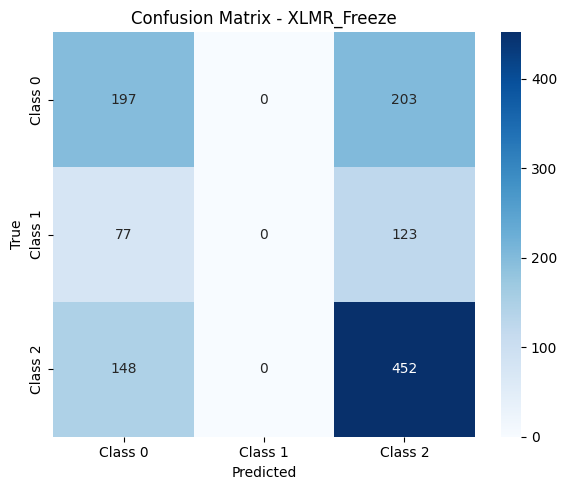

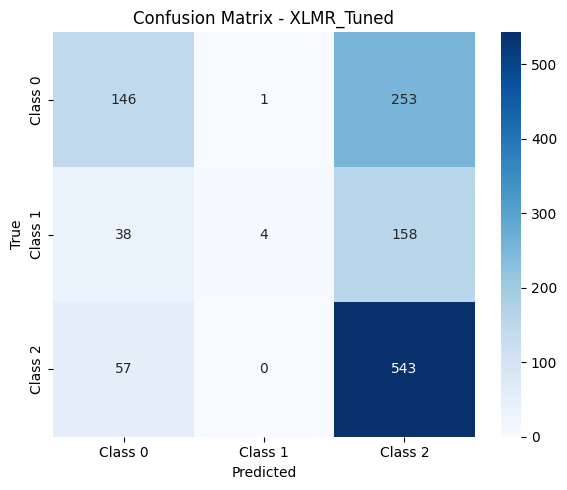

In [ ]:
SAVE_DIR = os.path.join(BASE_DIR, "cm_images")
os.makedirs(SAVE_DIR, exist_ok=True)

for name, cm in all_cms.items():
    save_path = os.path.join(SAVE_DIR, f"{name}.png")

    plot_confusion_matrix(
        cm,
        title=f"Confusion Matrix - {name}",
        class_names=class_names,
        normalize=False,
        save_path=save_path
    )

### Deep learning - Classical models approach

#### Note

In [ ]:
"""
Pipeline: Classical Deep Learning Models for Text (CNN / RNN / LSTM)

Objective:
Learn f: text → label using explicit tokenization and embedding.

--------------------------------------------------
I. INPUT PROCESSING

raw text
  ↓
Tokenizer (external, language-specific)
  ↓
tokens: [w1, w2, ..., wn]

Example (Vietnamese):
    "công nghệ thông tin"
    → ["công_nghệ", "thông_tin"]

--------------------------------------------------
II. VOCABULARY

Build vocabulary V from TRAIN set only:
    V = {w1, w2, ..., w_|V|}

Mapping:
    word → index ∈ {1,...,|V|}

OOV handling:
    unknown word → <UNK>

--------------------------------------------------
III. EMBEDDING

Option A: Learn from scratch
    E ∈ R^{|V| × d}

Option B: Pretrained (Word2Vec / GloVe / fastText)

Lookup:
    X = [E[w1], E[w2], ..., E[wn]]
    X ∈ R^{seq_len × d}

NOTE:
- Embeddings are static (no context awareness)
- Same word → same vector

--------------------------------------------------
IV. MODEL ARCHITECTURES

(A) CNN for Text

Apply 1D convolution:
    h = ReLU(Conv1D(X))

Capture n-gram features:
    kernel size k → k-gram patterns

Pooling:
    h_pool = max_pool(h)

--------------------------------------------------
(B) RNN / LSTM

Sequential modeling:
    h_t = LSTM(x_t, h_{t-1})

Final representation:
    h_final = h_n
    (or mean/max pooling over all h_t)

--------------------------------------------------
V. CLASSIFIER HEAD

Linear layer:
    z = W h + b
    W ∈ R^{C × d_hidden}

Softmax:
    p = softmax(z)

--------------------------------------------------
VI. TARGET

Ground truth:
    y ∈ {0,1,...,C-1}

--------------------------------------------------
VII. LOSS FUNCTION

Cross-entropy:
    L = - Σ_{c=1}^{C} y_c log(p_c)

--------------------------------------------------
VIII. FLOW CHART

text
 ↓
tokenizer (word-level)
 ↓
tokens
 ↓
word → index
 ↓
embedding lookup
 ↓
[CNN or LSTM]
 ↓
sentence representation
 ↓
linear classifier
 ↓
softmax
 ↓
prediction

--------------------------------------------------
IX. KEY PROPERTIES

- Requires explicit tokenization
- No contextual embeddings (static vectors)
- Sensitive to OOV and vocabulary quality
- CNN → local patterns (n-gram)
- LSTM → sequential dependencies
- Performance depends heavily on embedding quality

--------------------------------------------------
X. LIMITATIONS (vs Transformer)

- Cannot model context dynamically
- Requires more feature engineering
- Lower performance on complex NLP tasks

"""
''

''

#### Data Preparation

In [ ]:
data_cleaned['label'] = data_cleaned['rating'].apply(
    lambda x: 'negative' if x < 3 else ('neutral' if x == 3 else 'positive')
)

label_map = {
    'negative': 0,
    'neutral': 1,
    'positive': 2
}

data_cleaned['label_encoded'] = data_cleaned['label'].map(label_map)

In [ ]:
X = data_cleaned['reviewText']
y = data_cleaned['label_encoded']

In [ ]:
X_tr, X_temp, y_tr, y_temp = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=42
)

#### Models

![image](https://drive.google.com/uc?export=view&id=13Png3lL92SuGmzxDKGtVe8L-_L1rokIx)

In [ ]:
class TextCNN_W2V(nn.Module):
    """
      Mô hình TextCNN sử dụng Word2Vec Embedding cho phân loại văn bản.

      Luồng dữ liệu (Data flow) và xử lý chiều tensor:
      1. Embedding: `x` từ `(batch_size, seq_len)` thành `(batch_size, seq_len, embed_dim)`.
        Cho phép cập nhật trọng số (freeze=False) và bỏ qua token đệm (padding_idx=0).
      2. Permute: Đảo chiều thành `(batch_size, embed_dim, seq_len)` để đưa vào Conv1d
        (trong đó embed_dim đóng vai trò như 'channels').
      3. Conv1d: Cửa sổ trượt (kernel_size=5) quét 5-gram để tạo 128 đặc trưng (feature maps).
      4. AdaptiveMaxPool1d: Giữ lại giá trị đặc trưng lớn nhất (max pooling) trên toàn bộ
        chiều dài câu cho mỗi filter. Trả về `(batch_size, 128, 1)`.
      5. Squeeze(-1): Cắt bỏ chiều `1` thừa ở cuối thành `(batch_size, 128)` để đẩy vào lớp Fully Connected.
      """
    def __init__(self, embedding_matrix, num_classes):
        super().__init__()

        vocab_size, embed_dim = embedding_matrix.shape

        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, freeze=False, padding_idx=0
        )
        """
        Báo cho mô hình biết index 0 (thường là token <PAD>) là để đệm cho các
        câu dài bằng nhau. PyTorch sẽ không tính gradient cho index 0 này.

        Nghĩa là trong quá trình train (huấn luyện), trọng số của ma trận Word2Vec
        này được phép cập nhật (fine-tune) để phù hợp hơn với bài toán cụ thể
        """

        self.conv = nn.Conv1d(embed_dim, 128, kernel_size=5)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(0, 2, 1)
        x = self.conv(x)
        x = self.pool(x).squeeze(-1)
        return self.fc(x)

In [ ]:
class TextRNN_W2V(nn.Module):
    """
      Mô hình TextRNN sử dụng Word2Vec Embedding cho phân loại văn bản.

      Luồng dữ liệu (Data flow) và xử lý chiều tensor:
      1. Embedding: `x` biến đổi thành `(batch_size, seq_len, embed_dim)`.
      2. RNN: Xử lý tuần tự. `batch_first=True` giúp giữ nguyên chiều batch ở đầu.
        Hàm trả về output (tất cả các bước) và trạng thái ẩn cuối `h`.
        `h` có kích thước `(num_layers, batch_size, hidden_dim)`.
      3. Squeeze(0): Với num_layers=1, thao tác này xóa chiều đầu tiên,
        ép `h` gọn lại thành `(batch_size, hidden_dim)`.
      4. Lớp FC: Nhận vector tóm tắt `h` đã squeeze để dự đoán phân lớp.
      """
    def __init__(self, embedding_matrix, hidden_dim, num_classes):
        super().__init__()

        vocab_size, embed_dim = embedding_matrix.shape

        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, freeze=False, padding_idx=0
        )

        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        x = self.embedding(x)
        _, h = self.rnn(x)
        return self.fc(h.squeeze(0))

In [ ]:
class TextLSTM_W2V(nn.Module):
    """
      Mô hình TextLSTM sử dụng Word2Vec Embedding cho phân loại văn bản.

      Luồng dữ liệu (Data flow) và xử lý chiều tensor:
      1. Embedding: `x` biến đổi thành `(batch_size, seq_len, embed_dim)`.
      2. LSTM: Giải quyết vấn đề quên của RNN. Trả về trạng thái ẩn `h` (trí nhớ ngắn hạn)
        và cell state `c` (trí nhớ dài hạn). `h` có kích thước `(num_layers, batch_size, hidden_dim)`.
      3. Trích xuất h[-1]: Lấy an toàn trạng thái ẩn của lớp LSTM cuối cùng `h[-1]`
        (phòng trường hợp cấu hình num_layers > 1). Kết quả có kích thước `(batch_size, hidden_dim)`.
      4. Lớp FC: Dùng vector `h[-1]` để đưa qua mạng Linear phân loại.
      """
    def __init__(self, embedding_matrix, hidden_dim, num_classes):
        super().__init__()

        vocab_size, embed_dim = embedding_matrix.shape

        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, freeze=False, padding_idx=0
        )

        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        x = self.embedding(x)
        _, (h, _) = self.lstm(x)
        return self.fc(h[-1])

In [ ]:
class TextBiLSTM_W2V(nn.Module):
    """
      Mô hình TextBiLSTM (LSTM hai chiều) sử dụng Word2Vec Embedding cho phân loại.

      Luồng dữ liệu (Data flow) và xử lý chiều tensor:
      1. Embedding: `x` biến đổi thành `(batch_size, seq_len, embed_dim)`.
      2. BiLSTM (bidirectional=True): Học thông tin câu theo 2 chiều (trái->phải và phải->trái).
        Trạng thái ẩn `h` thu được có kích thước `(2 * num_layers, batch_size, hidden_dim)`.
      3. Tách chiều:
        - `h[-2]`: Vector tóm tắt câu của chiều đi xuôi (forward).
        - `h[-1]`: Vector tóm tắt câu của chiều đi ngược (backward).
      4. Concat: Dùng `torch.cat` ghép 2 chiều lại, tạo ra siêu tensor có kích thước
        `(batch_size, hidden_dim * 2)`.
      5. Lớp FC: Do học 2 chiều, lớp Linear nhận đầu vào nhân đôi là `hidden_dim * 2` để dự đoán.
      """
    def __init__(self, embedding_matrix, hidden_dim, num_classes):
        super().__init__()

        vocab_size, embed_dim = embedding_matrix.shape

        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix, freeze=False, padding_idx=0
        )

        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        x = self.embedding(x)
        _, (h, _) = self.lstm(x)
        h = torch.cat((h[-2], h[-1]), dim=1)
        return self.fc(h)

#### Config

In [ ]:
classic_configs = [
    {"name": "TextCNN_W2V", "model": "cnn"},
    {"name": "RNN_W2V", "model": "rnn"},
    {"name": "LSTM_W2V", "model": "lstm"},
    {"name": "BiLSTM_W2V", "model": "bilstm"},
]

#### Utils

In [ ]:
class Vocab:
    def __init__(self, w2v_model):
        self.w2v = w2v_model.wv
        self.itos = ['<pad>', '<unk>']
        self.stoi = {'<pad>': 0, '<unk>': 1}

        for word in self.w2v.index_to_key:
            self.stoi[word] = len(self.itos)
            self.itos.append(word)

    def encode(self, tokens):
        return [self.stoi.get(w, self.stoi['<unk>']) for w in tokens]


In [ ]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize_vi(text):
    text = preprocess_text(text)
    tokens = word_tokenize(text, format="text").split()
    return tokens

In [ ]:
tokenized_all = [tokenize_vi(text) for text in X]
print("Tokenization completed on full dataset.")

Tokenization completed on full dataset.


In [ ]:
def get_w2v_model(config, embedding_matrix, num_classes):

    if config["model"] == "cnn":
        return TextCNN_W2V(embedding_matrix, num_classes)

    elif config["model"] == "rnn":
        return TextRNN_W2V(embedding_matrix, 128, num_classes)

    elif config["model"] == "lstm":
        return TextLSTM_W2V(embedding_matrix, 128, num_classes)

    elif config["model"] == "bilstm":
        return TextBiLSTM_W2V(embedding_matrix, 128, num_classes)

    else:
        raise ValueError("Unknown model type")

In [ ]:
def collate_fn(batch):
    texts, labels = zip(*batch)

    texts = [torch.tensor(t, dtype=torch.long) for t in texts]
    texts = pad_sequence(texts, batch_first=True, padding_value=0)

    labels = torch.tensor(labels, dtype=torch.long)

    return texts, labels

In [ ]:
tokenized_tr = [tokenize_vi(text) for text in X_tr]
tokenized_val = [tokenize_vi(text) for text in X_val]
tokenized_test = [tokenize_vi(text) for text in X_test]

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch in loader:

        if isinstance(batch, dict):  # transformer
            inputs = batch['input_ids'].to(device)
            labels = batch['labels'].to(device)
            outputs = model(input_ids=inputs, labels=None).logits
        else:  # W2V / classic
            inputs, labels = batch
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)

        optimizer.zero_grad()
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return running_loss / total, 100. * correct / total

In [ ]:
def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch in loader:

            if isinstance(batch, dict):
                inputs = batch['input_ids'].to(device)
                labels = batch['labels'].to(device)
                outputs = model(input_ids=inputs, labels=None).logits
            else:
                inputs, labels = batch
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * labels.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    return running_loss / total, 100. * correct / total

#### Building Word2Vec

##### Note

In [ ]:
"""
Train a Word2Vec embedding model using the Skip-gram architecture.

This code initializes and trains a Word2Vec model on tokenized text data.
Unlike typical ML frameworks, the Word2Vec constructor in gensim performs
the full training process internally (equivalent to `.fit()`).

--------------------------------------------------
INPUT:
- sentences: List of tokenized sentences
    Example:
        [["i", "love", "nlp"], ["nlp", "is", "fun"]]

--------------------------------------------------
MODEL CONFIGURATION:

- vector_size (int):
    Dimensionality of word embeddings (e.g., 100)

- window (int):
    Maximum distance between the current word and context words.
    Defines the size of the context window.

- min_count (int):
    Ignores words with total frequency lower than this threshold.

- workers (int):
    Number of parallel worker threads used for training.

- sg (int):
    Training algorithm:
        0 = CBOW (context → target)
        1 = Skip-gram (target → context)

--------------------------------------------------
TRAINING MECHANISM:

1. Build vocabulary from input sentences.
2. Generate (target, context) training pairs using sliding window.
3. Optimize embeddings using Skip-gram with negative sampling:

    Objective:
        Maximize P(context | target)

    Loss:
        L = -log σ(v_c · v_t) - Σ log σ(-v_n · v_t)

4. Update embedding vectors via stochastic gradient descent.

--------------------------------------------------
OUTPUT:

- w2v_model.wv[word]:
    Returns dense vector representation of the word.

- w2v_model.wv.most_similar(word):
    Returns semantically similar words based on cosine similarity.

--------------------------------------------------
KEY PROPERTIES:

- Learns static embeddings (no context awareness).
- Captures semantic similarity through co-occurrence statistics.
- Efficient for large corpora.
"""
''

''

In [ ]:
"""
Quy trình tiền xử lý và nhúng từ (Embedding) cho mô hình NLP (LSTM/CNN-text).

Luồng thực hiện chuẩn (Standard Pipeline):
    1. Tokenization (underthesea): Thực hiện trên TOÀN BỘ dữ liệu trước cho tiện.
    2. Data Split: Chia dữ liệu thành các tập Train / Validation / Test.
    3. Build Vocab & Word2Vec: BẮT BUỘC chỉ khởi tạo và huấn luyện trên tập TRAIN
       để chặn tuyệt đối hiện tượng rò rỉ dữ liệu (Data Leakage).
    4. Text-to-Sequences & Padding: Áp dụng từ điển (Vocab) của tập Train để
       chuyển đổi cả 3 tập thành chuỗi số (gán từ lạ là <UNK>) và đệm (pad) bằng độ dài.
"""
''

''

##### Train

In [ ]:
w2v_model = Word2Vec(
    sentences=tokenized_tr,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

print("Word2Vec training completed on training set.")

Word2Vec training completed on training set.


In [ ]:
vocab = Vocab(w2v_model)
print(f"Vocabulary size: {len(vocab.itos)}")

Vocabulary size: 17369


In [ ]:
embed_dim = w2v_model.vector_size

embedding_matrix = np.zeros((len(vocab.itos), embed_dim))

for word, idx in vocab.stoi.items():
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]
    else:
        embedding_matrix[idx] = np.random.normal(scale=0.6, size=(embed_dim,))

embedding_matrix = torch.tensor(embedding_matrix, dtype=torch.float32)

print(f"Embedding matrix shape: {embedding_matrix.shape}")

Embedding matrix shape: torch.Size([17369, 100])


#### Building Dataset

In [ ]:
class TextDatasetW2V(Dataset):
    def __init__(self, tokenized_texts, labels, vocab):
        self.texts = tokenized_texts
        self.labels = labels.tolist()
        self.vocab = vocab

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = torch.tensor(self.vocab.encode(self.texts[idx]), dtype=torch.long)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return encoded, label

In [ ]:
def prepare_w2v_dataloaders(tokenized_tr, tokenized_val, tokenized_test,
                            y_tr, y_val, y_test,
                            vocab, batch_size=32):

    train_dataset = TextDatasetW2V(tokenized_tr, y_tr, vocab)
    val_dataset   = TextDatasetW2V(tokenized_val, y_val, vocab)
    test_dataset  = TextDatasetW2V(tokenized_test, y_test, vocab)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
    val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

    return train_loader, val_loader, test_loader

In [ ]:
train_loader, val_loader, test_loader = prepare_w2v_dataloaders(
    tokenized_tr, tokenized_val, tokenized_test,
    y_tr, y_val, y_test,
    vocab,
    batch_size=32
)

print("W2V DataLoaders initialized successfully.")

W2V DataLoaders initialized successfully.


#### Training models

In [ ]:
BASE_DIR = "/content/drive/MyDrive/P4AIDS-Assignment/Text/experiments_classic"
os.makedirs(BASE_DIR, exist_ok=True)

CSV_PATH = os.path.join(BASE_DIR, "results_classic.csv")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
HIST_DIR = os.path.join(BASE_DIR, "histories")
CM_DIR = os.path.join(BASE_DIR, "confusion_matrices")

os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(HIST_DIR, exist_ok=True)
os.makedirs(CM_DIR, exist_ok=True)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
final_results_classic = []
all_histories_classic = {}
all_confusion_matrices_classic = {}

criterion = nn.CrossEntropyLoss()

for cfg in classic_configs:

    print(f"\nTraining: {cfg['name']}")

    model_name = cfg['name']  #

    model = get_w2v_model(cfg, embedding_matrix, num_classes=3).to(device)

    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    scheduler = None

    start_train = time.time()

    model, history = train_model(
        model,
        train_loader,
        val_loader,
        criterion,
        optimizer,
        scheduler,
        device,
        num_epochs=8,
        model_name=cfg["name"]
    )

    train_duration = (time.time() - start_train) / 60

    metrics = evaluate_comprehensive(model, test_loader, device)

    all_confusion_matrices_classic[cfg['name']] = metrics['cm']
    all_histories_classic[cfg['name']] = history

    total_p, train_p = count_parameters(model)

    final_results_classic.append({
        "Model Name": cfg["name"],
        "Architecture": "W2V + " + cfg["model"],
        "Strategy": "train_from_scratch",
        "Accuracy (%)": f"{metrics['acc']:.2f}",
        "F1 Score (%)": f"{metrics['f1']:.2f}",
        "Inference (ms/sample)": f"{metrics['inf_time']:.2f}",
        "VRAM (MB)": f"{metrics['memory']:.1f}",
        "Train Time (min)": f"{train_duration:.1f}",
        "Total Params (M)": f"{total_p:.2f}",
        "Trainable Params (M)": f"{train_p:.2f}"
    })

    # ====== ADD: SAVE AFTER EACH CONFIG ======

    # 1. SAVE CSV (append từng dòng)
    df_row = pd.DataFrame([final_results_classic[-1]])

    if not os.path.exists(CSV_PATH):
        df_row.to_csv(CSV_PATH, index=False)
    else:
        df_row.to_csv(CSV_PATH, mode='a', header=False, index=False)

    # 2. SAVE CHECKPOINT
    ckpt_path = os.path.join(CKPT_DIR, f"{model_name}.pt")
    torch.save({
        'model_state_dict': model.state_dict(),
        'config': cfg,
        'metrics': metrics
    }, ckpt_path)

    # 3. SAVE HISTORY
    hist_path = os.path.join(HIST_DIR, f"{model_name}_history.pt")
    torch.save(history, hist_path)

    # 4. SAVE CONFUSION MATRIX
    cm_path = os.path.join(CM_DIR, f"{model_name}_cm.pt")
    torch.save(metrics['cm'], cm_path)

    print(f" Saved everything for {model_name}")


Training: TextCNN_W2V
Starting training on cuda...
------------------------------
Epoch 1/8:
  Train Loss: 0.9854 | Acc: 50.91%
  Val Loss:   0.9442 | Acc: 56.46%
Saving weights...
Epoch 2/8:
  Train Loss: 0.8785 | Acc: 63.84%
  Val Loss:   0.8379 | Acc: 69.39%
Saving weights...
Epoch 3/8:
  Train Loss: 0.7768 | Acc: 69.96%
  Val Loss:   0.7652 | Acc: 69.89%
Saving weights...
Epoch 4/8:
  Train Loss: 0.7146 | Acc: 71.64%
  Val Loss:   0.7272 | Acc: 71.48%
Saving weights...
Epoch 5/8:
  Train Loss: 0.6729 | Acc: 73.02%
  Val Loss:   0.7075 | Acc: 71.31%
Epoch 6/8:
  Train Loss: 0.6427 | Acc: 74.06%
  Val Loss:   0.6932 | Acc: 71.89%
Saving weights...
Epoch 7/8:
  Train Loss: 0.6155 | Acc: 75.08%
  Val Loss:   0.6818 | Acc: 72.23%
Saving weights...
Epoch 8/8:
  Train Loss: 0.5921 | Acc: 76.25%
  Val Loss:   0.6683 | Acc: 72.73%
Saving weights...
------------------------------
Training complete in 5m 2s
Best Val Acc: 72.727273%
 Saved everything for TextCNN_W2V

Training: RNN_W2V
Startin

In [ ]:
/content/drive/MyDrive/P4AIDS-Assignment/Text/experiments_classic (2)

#### Evaluation

In [ ]:
BASE_DIR = "/content/drive/MyDrive/P4AIDS-Assignment/Text/experiments_classic"

CSV_PATH = os.path.join(BASE_DIR, "results_classic.csv")
HIST_DIR = os.path.join(BASE_DIR, "histories")
CM_DIR = os.path.join(BASE_DIR, "confusion_matrices")

SAVE_DIR = os.path.join(BASE_DIR, "visualizations")
os.makedirs(SAVE_DIR, exist_ok=True)

In [ ]:
# ===== CSV =====
df = pd.read_csv(CSV_PATH)

# convert string → float
for col in [
    "Accuracy (%)", "F1 Score (%)",
    "Inference (ms/sample)", "VRAM (MB)",
    "Train Time (min)", "Total Params (M)"
]:
    df[col] = pd.to_numeric(df[col])

# ===== HISTORIES =====
all_histories = {}

for file in os.listdir(HIST_DIR):
    if file.endswith("_history.pt"):
        name = file.replace("_history.pt", "")
        path = os.path.join(HIST_DIR, file)

        hist = torch.load(path, weights_only=False)
        all_histories[name] = hist

# ===== CONFUSION MATRICES =====
all_cms = {}

for file in os.listdir(CM_DIR):
    if file.endswith("_cm.pt"):
        name = file.replace("_cm.pt", "")
        path = os.path.join(CM_DIR, file)

        cm = torch.load(path, weights_only=False)

        if isinstance(cm, torch.Tensor):
            cm = cm.cpu().numpy()

        all_cms[name] = cm

print("Loaded:", list(all_histories.keys()))

Loaded: ['TextCNN_W2V', 'RNN_W2V', 'LSTM_W2V', 'BiLSTM_W2V']


In [ ]:
def plot_all_cms(all_cms, class_names, save_dir):
    for name, cm in all_cms.items():

        # ===== RAW =====
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=class_names,
                    yticklabels=class_names)

        plt.title(f"CM - {name}")
        plt.xlabel("Predicted")
        plt.ylabel("True")

        plt.savefig(os.path.join(save_dir, f"{name}_cm.png"), dpi=300)
        plt.show()

        # ===== NORMALIZED =====
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

        plt.figure(figsize=(6,5))
        sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                    xticklabels=class_names,
                    yticklabels=class_names)

        plt.title(f"Normalized CM - {name}")
        plt.xlabel("Predicted")
        plt.ylabel("True")

        plt.savefig(os.path.join(save_dir, f"{name}_cm_norm.png"), dpi=300)
        plt.show()

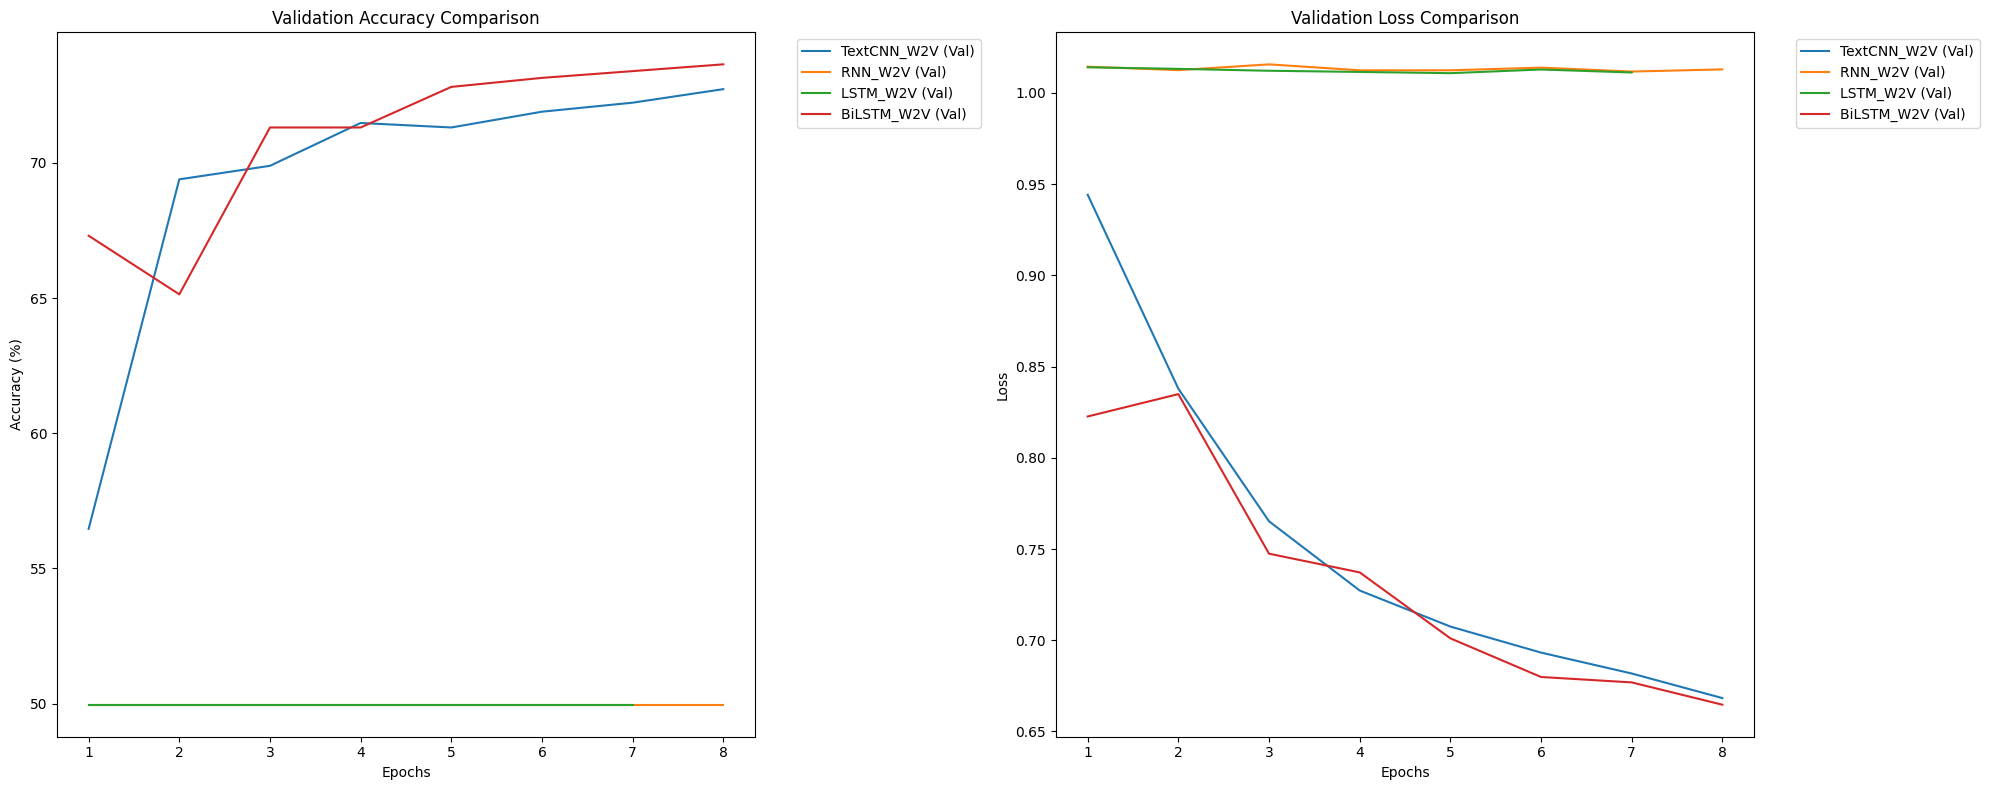

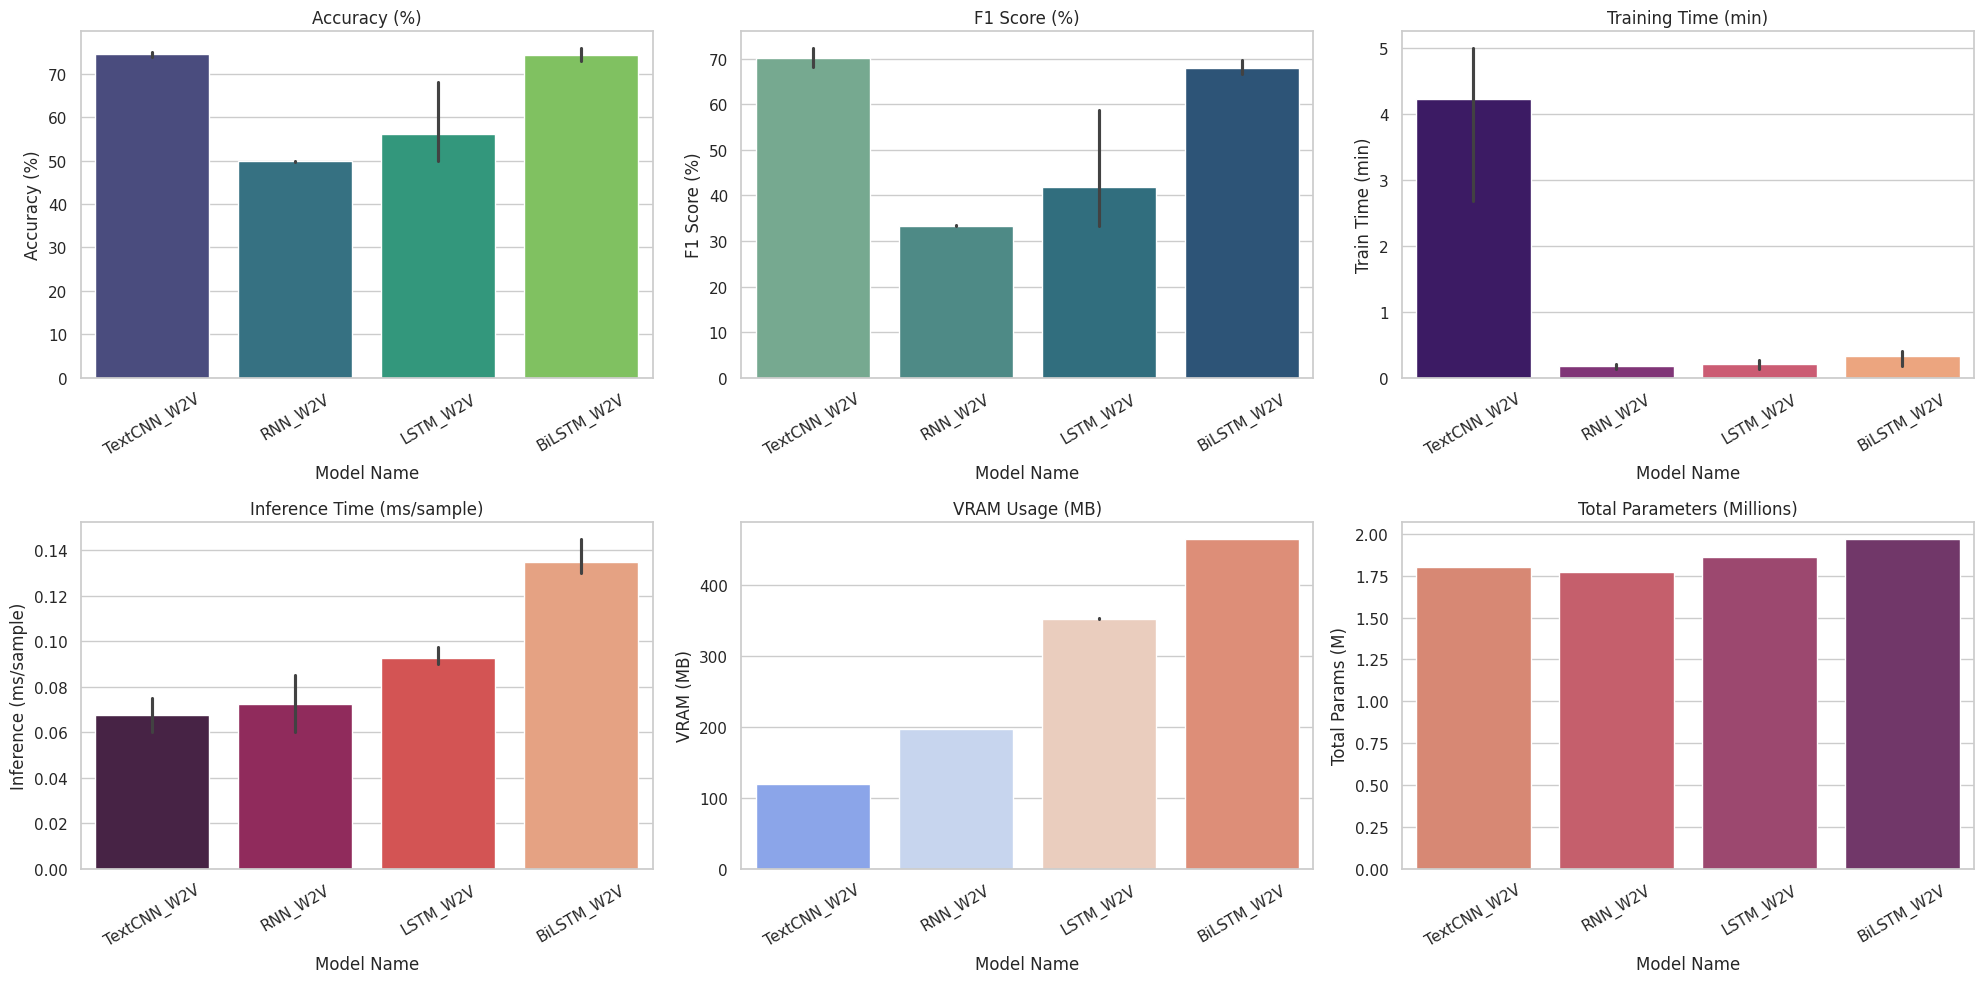

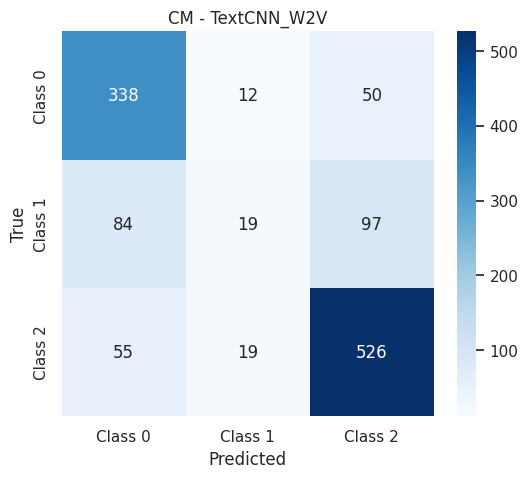

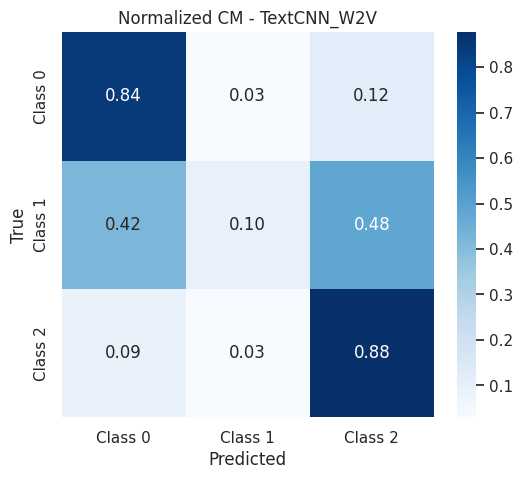

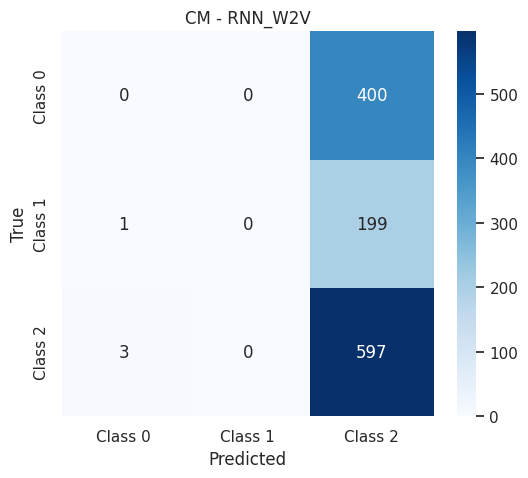

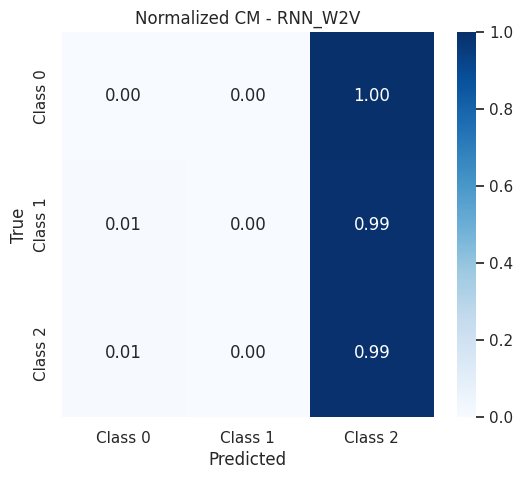

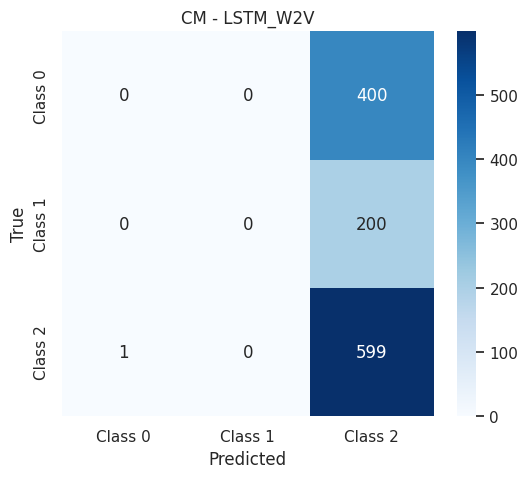

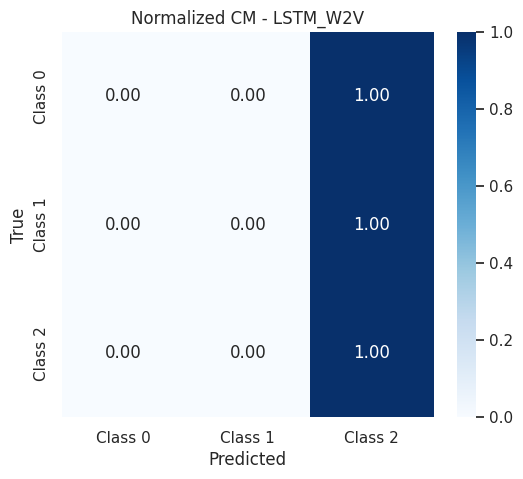

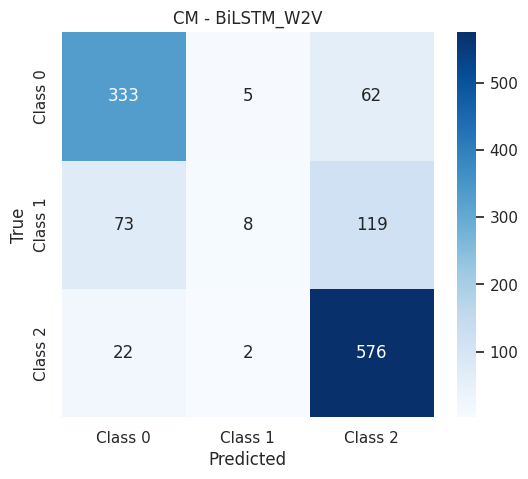

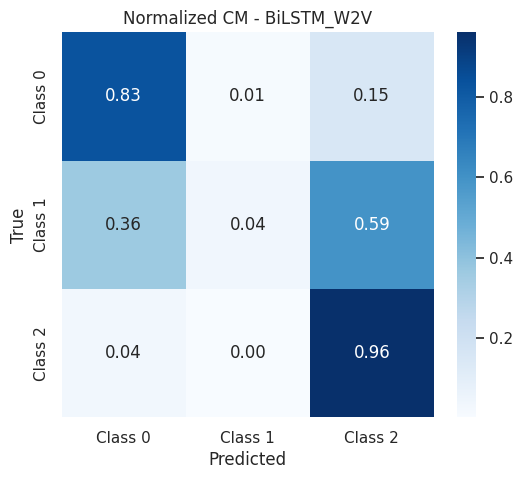

In [ ]:
class_names = ["Class 0", "Class 1", "Class 2"]  # chỉnh lại nếu cần

# 1. Training curves
plot_all_histories(
    all_histories
)

# 2. Model comparison
plot_comparisons(
    df
)

# 3. Confusion matrices
plot_all_cms(
    all_cms,
    class_names,
    SAVE_DIR
)